##Análisis de cobertura minera en Huepetuhe (Parte 2)

A. Clasificación a partir de MapBiomas Perú
Se debe descargar el archivo.GEOTIFF resultante del Notebook anterior o bien descargarlo del siguiente drive: https://drive.google.com/drive/folders/1mf1qlQ9TBVUBh78AbAo5m-lwrAUZBuic

In [ ]:
!pip install rioxarray rasterio planetary-computer pystac-client cartopy geopandas matplotlib -q

In [ ]:
import numpy as np
import xarray as xr
import rioxarray
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import cartopy

In [ ]:
#abrir el .geotiff resultante del ejercicio anterior
features_recortado = rioxarray.open_rasterio("Huepetuhe_2016_Stack_12Bandas.tif")

In [ ]:
nombres_bandas = [
    "B02", "B03", "B04", "B08", "B11", "B12",
    "NDVI", "NDWI", "MNDWI", "BSI", "NDMI", "SWIR_RATIO"
]
features_recortado = features_recortado.assign_coords(band=nombres_bandas)

In [ ]:
print("Dimensiones (Bandas, Y, X):", features_recortado.shape)
print("CRS:", features_recortado.rio.crs)
print("Capas disponibles:", features_recortado.band.values)

Dimensiones (Bandas, Y, X): (12, 2160, 3492)
CRS: EPSG:32718
Capas disponibles: ['B02' 'B03' 'B04' 'B08' 'B11' 'B12' 'NDVI' 'NDWI' 'MNDWI' 'BSI' 'NDMI'
 'SWIR_RATIO']


In [ ]:
#seleccionamos los indices anteriores
ndvi  = features_recortado.sel(band="NDVI").values
bsi   = features_recortado.sel(band="BSI").values
mndwi = features_recortado.sel(band="MNDWI").values
swir1 = features_recortado.sel(band="B11").values

In [ ]:
mapa_clasificado = np.zeros(ndvi.shape, dtype=np.uint8)
valido = ~np.isnan(ndvi)

In [ ]:
#añadimos las categorías de mapbiomas
cond_agua    = valido & (mndwi > 0.0)
cond_mineria = valido & (~cond_agua) & (ndvi < 0.28) & (bsi > 0.02) & (swir1 > 0.14)
cond_sin_veg = valido & (~cond_agua) & (~cond_mineria) & (ndvi < 0.28)
cond_sec     = valido & (ndvi >= 0.28) & (ndvi < 0.65)
cond_bosque  = valido & (ndvi >= 0.65)

mapa_clasificado[cond_agua]    = 33  # Río, lago y pozas mineras
mapa_clasificado[cond_mineria] = 30  # Minería
mapa_clasificado[cond_sin_veg] = 25  # Otras áreas sin vegetación / playas fluviales
mapa_clasificado[cond_sec]     = 15  # Agropecuario / Vegetación secundaria
mapa_clasificado[cond_bosque]  = 3   # Bosque

In [ ]:
da_clasificado = xr.DataArray(
    mapa_clasificado,
    coords={"y": features_recortado.y, "x": features_recortado.x},
    dims=["y", "x"]
)
da_clasificado.rio.write_crs(features_recortado.rio.crs, inplace=True)
da_clasificado.rio.to_raster("Huepetuhe_Clasificacion_MapBiomas.tif", compress="LZW")

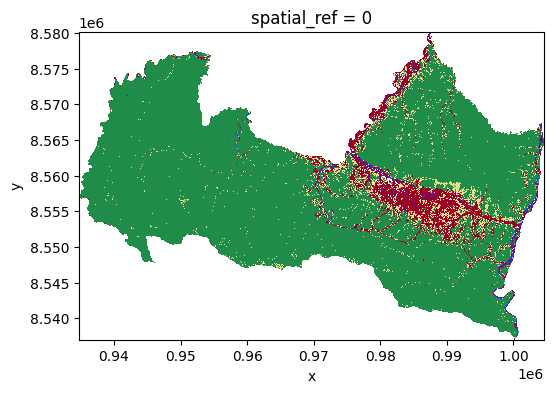

In [ ]:
#establecemos las clases de interés de MapBiomas
clases_info = {
    3:  ("3 - Bosque", "#1f8d49"),
    15: ("15 - Agropecuario / Veg. Secundaria", "#edde8e"),
    25: ("25 - Otras áreas sin vegetación", "#db4d4f"),
    30: ("30 - Minería", "#9c0027"),
    33: ("33 - Río, lago y pozas", "#2532e4"),
}

colores = [clases_info[c][1] for c in clases_info]
cmap_mb = mcolors.ListedColormap(colores)
norm = mcolors.BoundaryNorm([2, 10, 20, 28, 31, 35], cmap_mb.N)
fig, ax = plt.subplots(figsize=(6, 4))
da_clasificado.where(da_clasificado > 0).plot(ax=ax, cmap=cmap_mb, norm=norm, add_colorbar=False)




--- Superficie Estimada por Categoría (ha) ---
3 - Bosque                            : 131,418.92 ha
15 - Agropecuario / Veg. Secundaria   : 8,593.96 ha
25 - Otras áreas sin vegetación       : 467.80 ha
30 - Minería                          : 10,697.00 ha
33 - Río, lago y pozas                : 1,586.24 ha


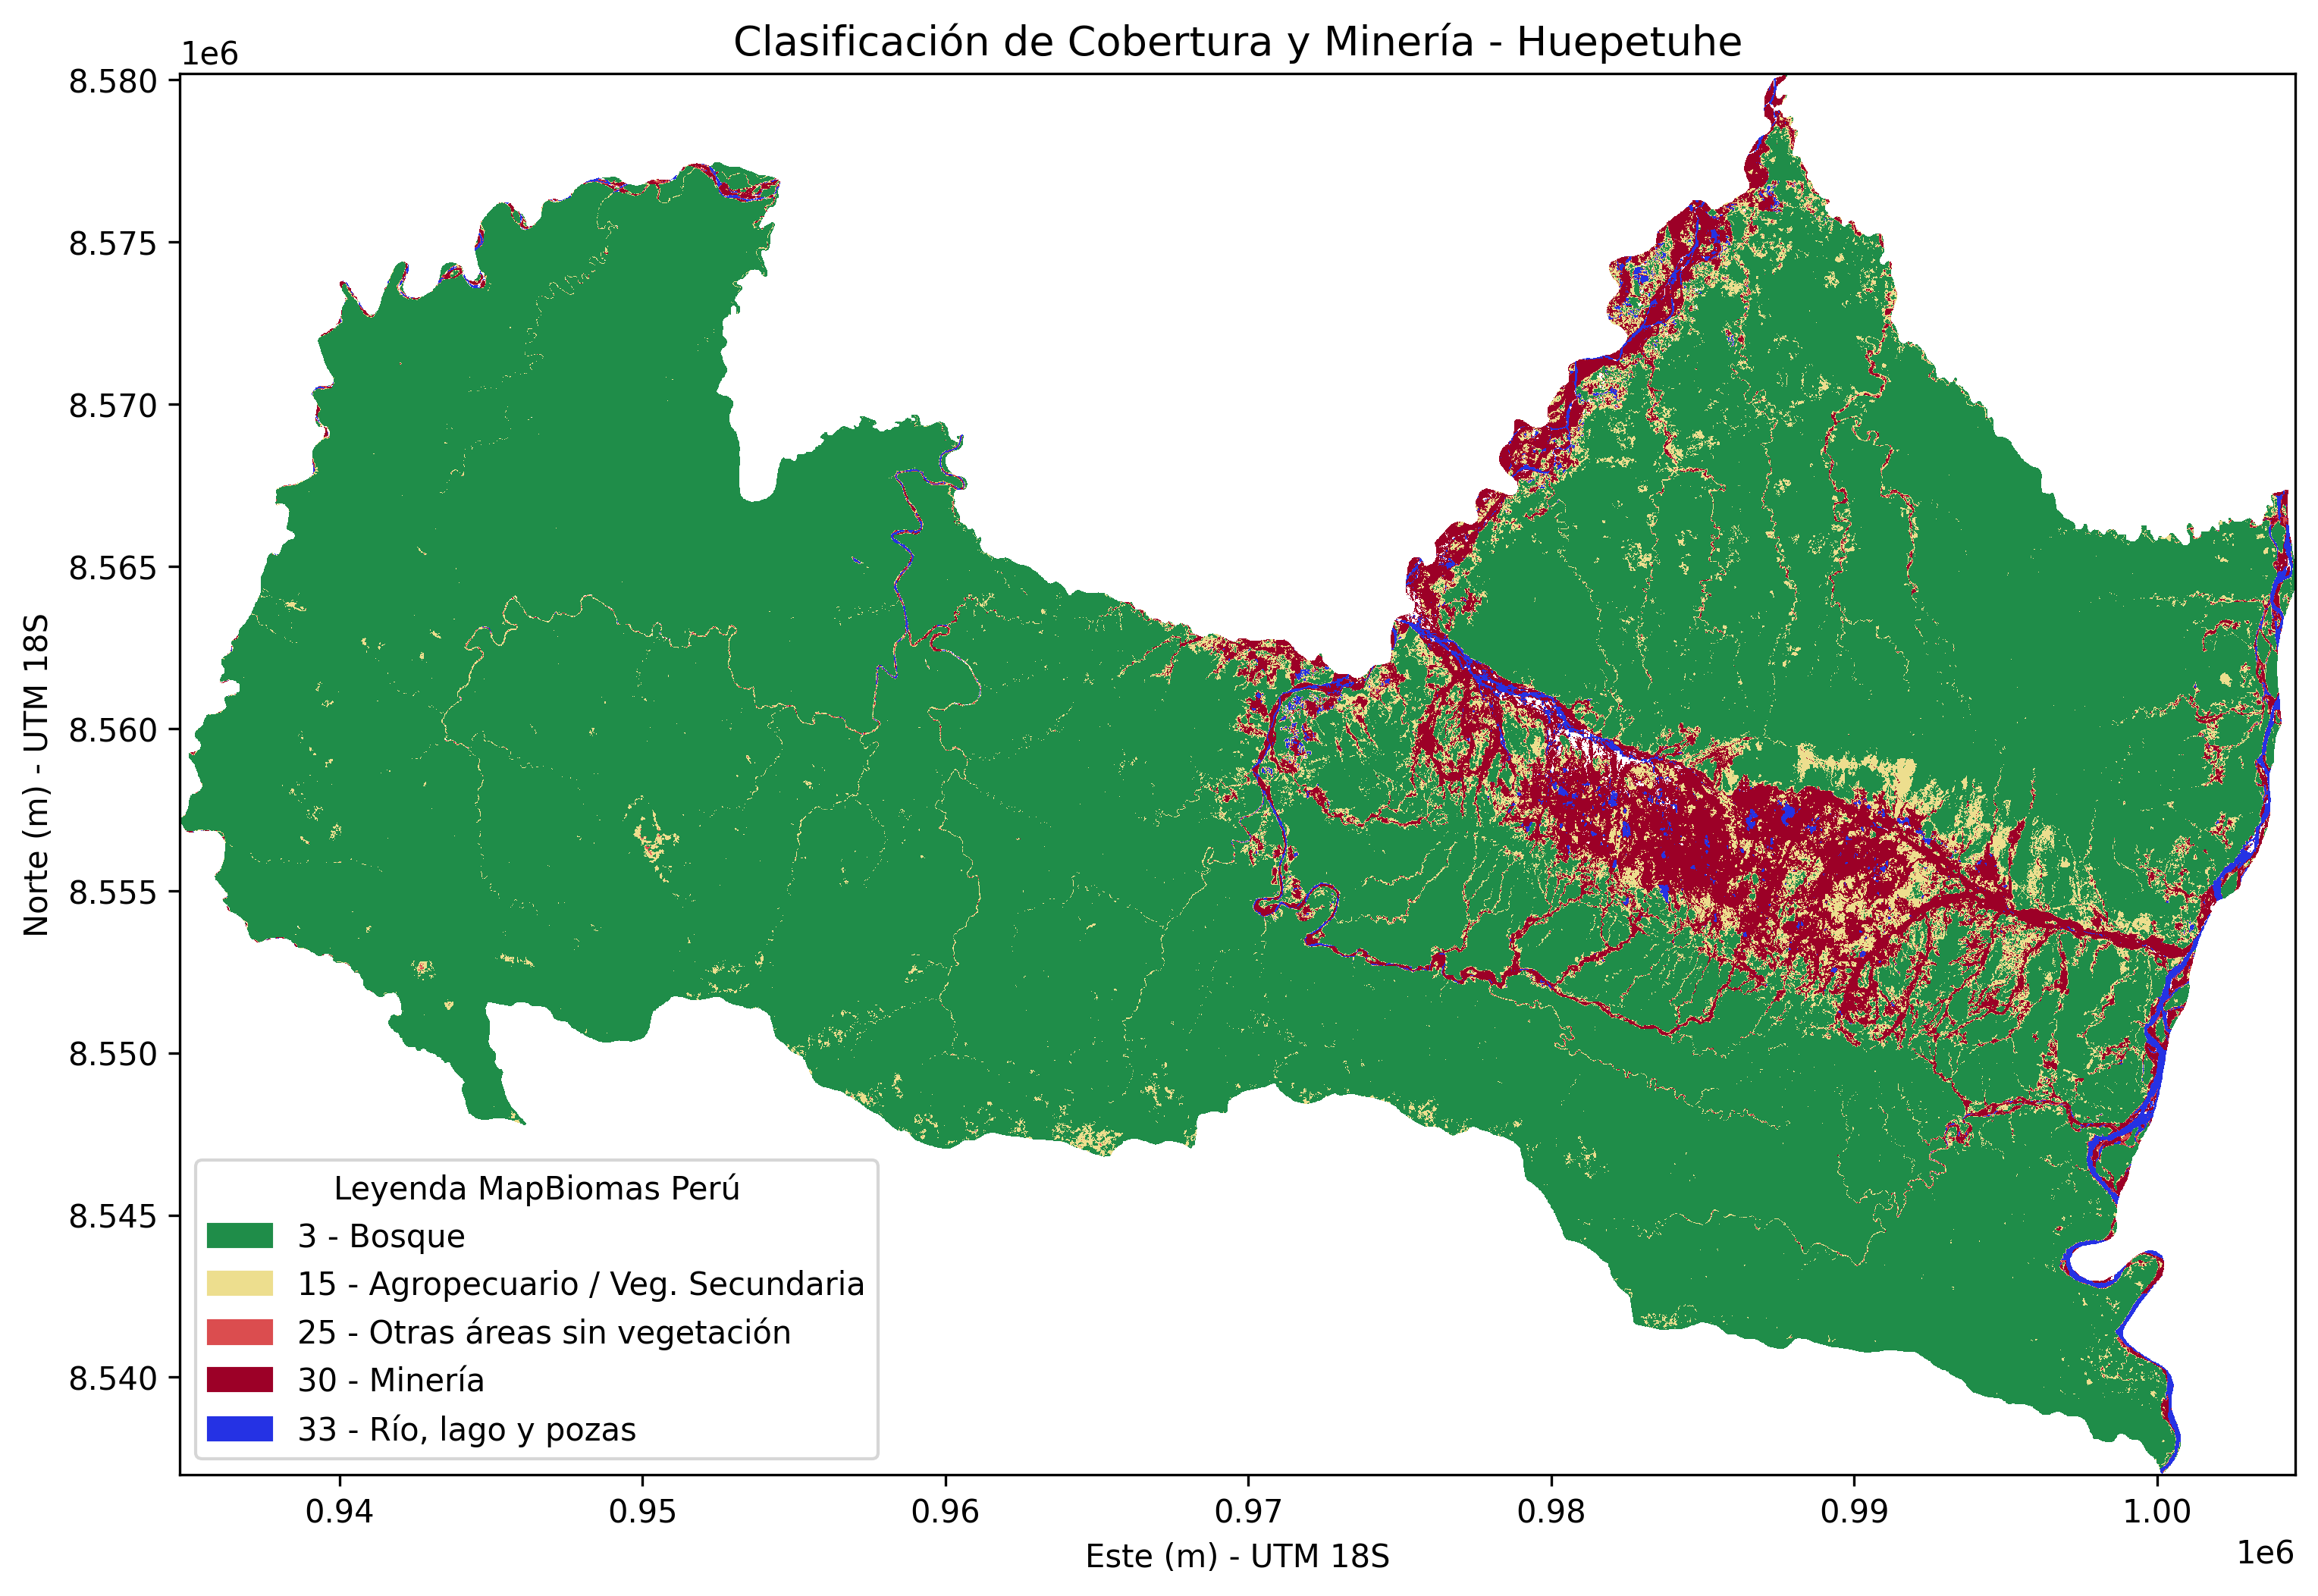

In [ ]:
#clasificación Mapbiomas no supervizado
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)
da_clasificado.where(da_clasificado > 0).plot(ax=ax, cmap=cmap_mb, norm=norm, add_colorbar=False)

parches = [mpatches.Patch(color=col, label=lbl) for lbl, col in clases_info.values()]
ax.legend(handles=parches, loc="lower left", title="Leyenda MapBiomas Perú", frameon=True)
ax.set_title("Clasificación de Cobertura y Minería - Huepetuhe", fontsize=13)
ax.set_xlabel("Este (m) - UTM 18S")
ax.set_ylabel("Norte (m) - UTM 18S") #visualizamos

print("\n--- Superficie Estimada por Categoría (ha) ---")
for cod, (nombre, _) in clases_info.items():
    hectareas = np.sum(mapa_clasificado == cod) * 0.04
    print(f"{nombre:<38}: {hectareas:,.2f} ha") #calculo de hectareas

plt.show()

B. Entrenamiento del modelo con Random Forest

In [ ]:
from rasterio.enums import Resampling
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [ ]:
stack = rioxarray.open_rasterio("Huepetuhe_2016_Stack_12Bandas.tif")
nombres_bandas = [
    "B02", "B03", "B04", "B08", "B11", "B12",
    "NDVI", "NDWI", "MNDWI", "BSI", "NDMI", "SWIR_RATIO"
]
stack = stack.assign_coords(band=nombres_bandas) #nombramos a las bandas

In [ ]:
mapbiomas = rioxarray.open_rasterio("/content/Huepetuhe_Clasificacion_MapBiomas.tif").squeeze()
mapbiomas_alineado = mapbiomas.rio.reproject_match(
    stack,
    resampling=Resampling.nearest  # Conserva los códigos enteros exactos (3, 15, 25, 30, 33)
) #reproyecta

In [ ]:
X_cubo = np.moveaxis(stack.values, 0, -1)
n_filas, n_cols, n_bandas = X_cubo.shape

X_flat = X_cubo.reshape(-1, n_bandas)
y_flat = mapbiomas_alineado.values.reshape(-1) #datos a tablas para el entrenamiento

In [ ]:
clases_interes = [3, 15, 18, 25, 30, 33]#crea clases
mascara_validos = (~np.isnan(X_flat).any(axis=1)) & np.isin(y_flat, clases_interes)#filtra los valores nan

X_valid = X_flat[mascara_validos]
y_valid = y_flat[mascara_validos].astype(int)#limpia datos

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_valid, y_valid, #divide datos
    train_size=0.2, #20% entrenamiento y 80% para evaluar
    stratify=y_valid, #mantinene valance
    random_state=42 #fija aleatoriedad
)

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=18,
    min_samples_leaf=10,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42
) #entrenamos el modelo con RandomForest
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced_subsample', max_depth=18,
                       min_samples_leaf=10, n_estimators=200, n_jobs=-1,
                       random_state=42)

In [ ]:
y_pred = rf.predict(X_test)
print(f"Exactitud Global (Overall Accuracy): {accuracy_score(y_test, y_pred):.2%}\n")
print("--- Reporte de Clasificación (Random Forest) ---")
print(classification_report(y_test, y_pred)) #vemos la clasificación de pixeles

Exactitud Global (Overall Accuracy): 100.00%

--- Reporte de Clasificación (Random Forest) ---
              precision    recall  f1-score   support

           3       1.00      1.00      1.00   2628379
          15       1.00      1.00      1.00    171879
          25       1.00      1.00      1.00      9356
          30       1.00      1.00      1.00    213940
          33       1.00      1.00      1.00     31725

    accuracy                           1.00   3055279
   macro avg       1.00      1.00      1.00   3055279
weighted avg       1.00      1.00      1.00   3055279



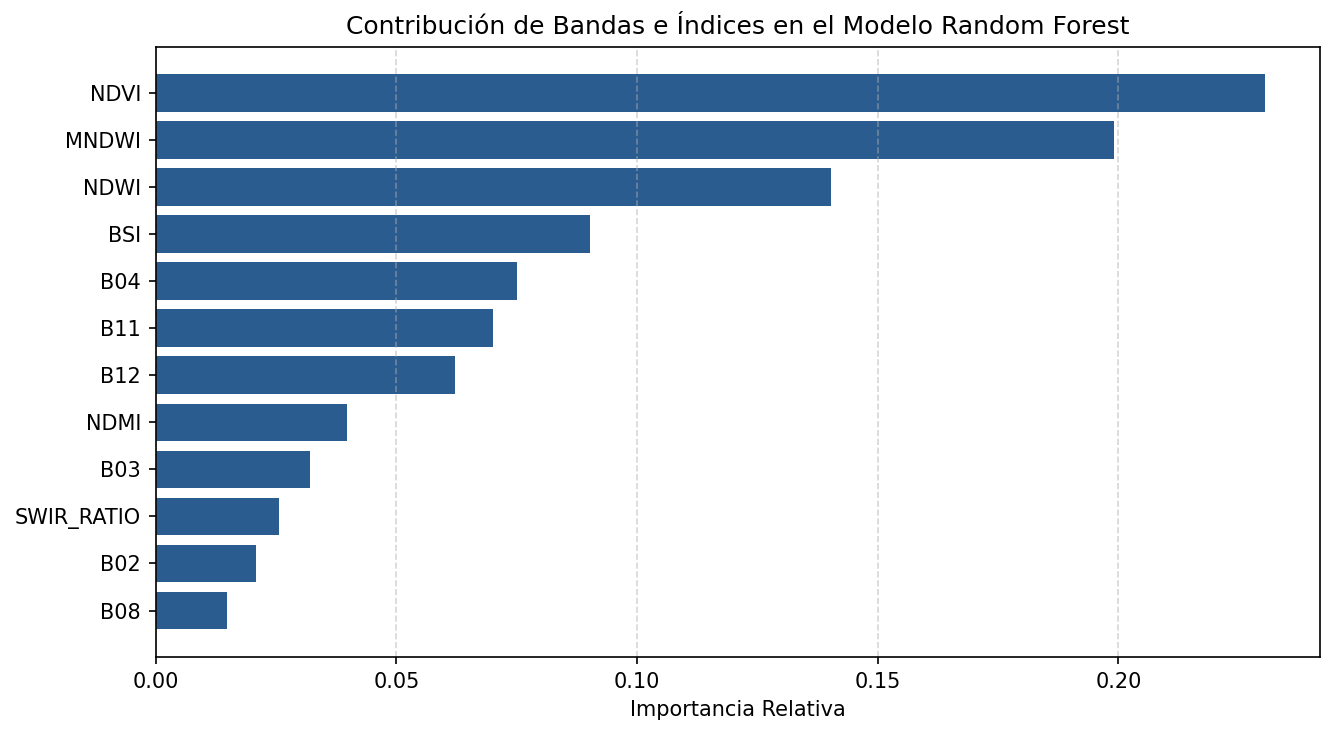

In [ ]:
importancias = rf.feature_importances_
indices_ord = np.argsort(importancias)

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)
ax.barh([nombres_bandas[i] for i in indices_ord], importancias[indices_ord], color="#2b5c8f")
ax.set_xlabel("Importancia Relativa")
ax.set_title("Contribución de Bandas e Índices en el Modelo Random Forest")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show() #graficamos según la contribución de las bandas

In [ ]:
predicciones = np.zeros(X_flat.shape[0], dtype=np.uint8)
mascara_no_nan = ~np.isnan(X_flat).any(axis=1)
predicciones[mascara_no_nan] = rf.predict(X_flat[mascara_no_nan])

mapa_rf = predicciones.reshape(n_filas, n_cols) #resultado tras random forest

In [ ]:
da_rf = xr.DataArray(
    mapa_rf,
    coords={"y": stack.y, "x": stack.x},
    dims=["y", "x"]
)
da_rf.rio.write_crs(stack.rio.crs, inplace=True)
da_rf.rio.to_raster("Huepetuhe_RandomForest_MapBiomas.tif", compress="LZW")

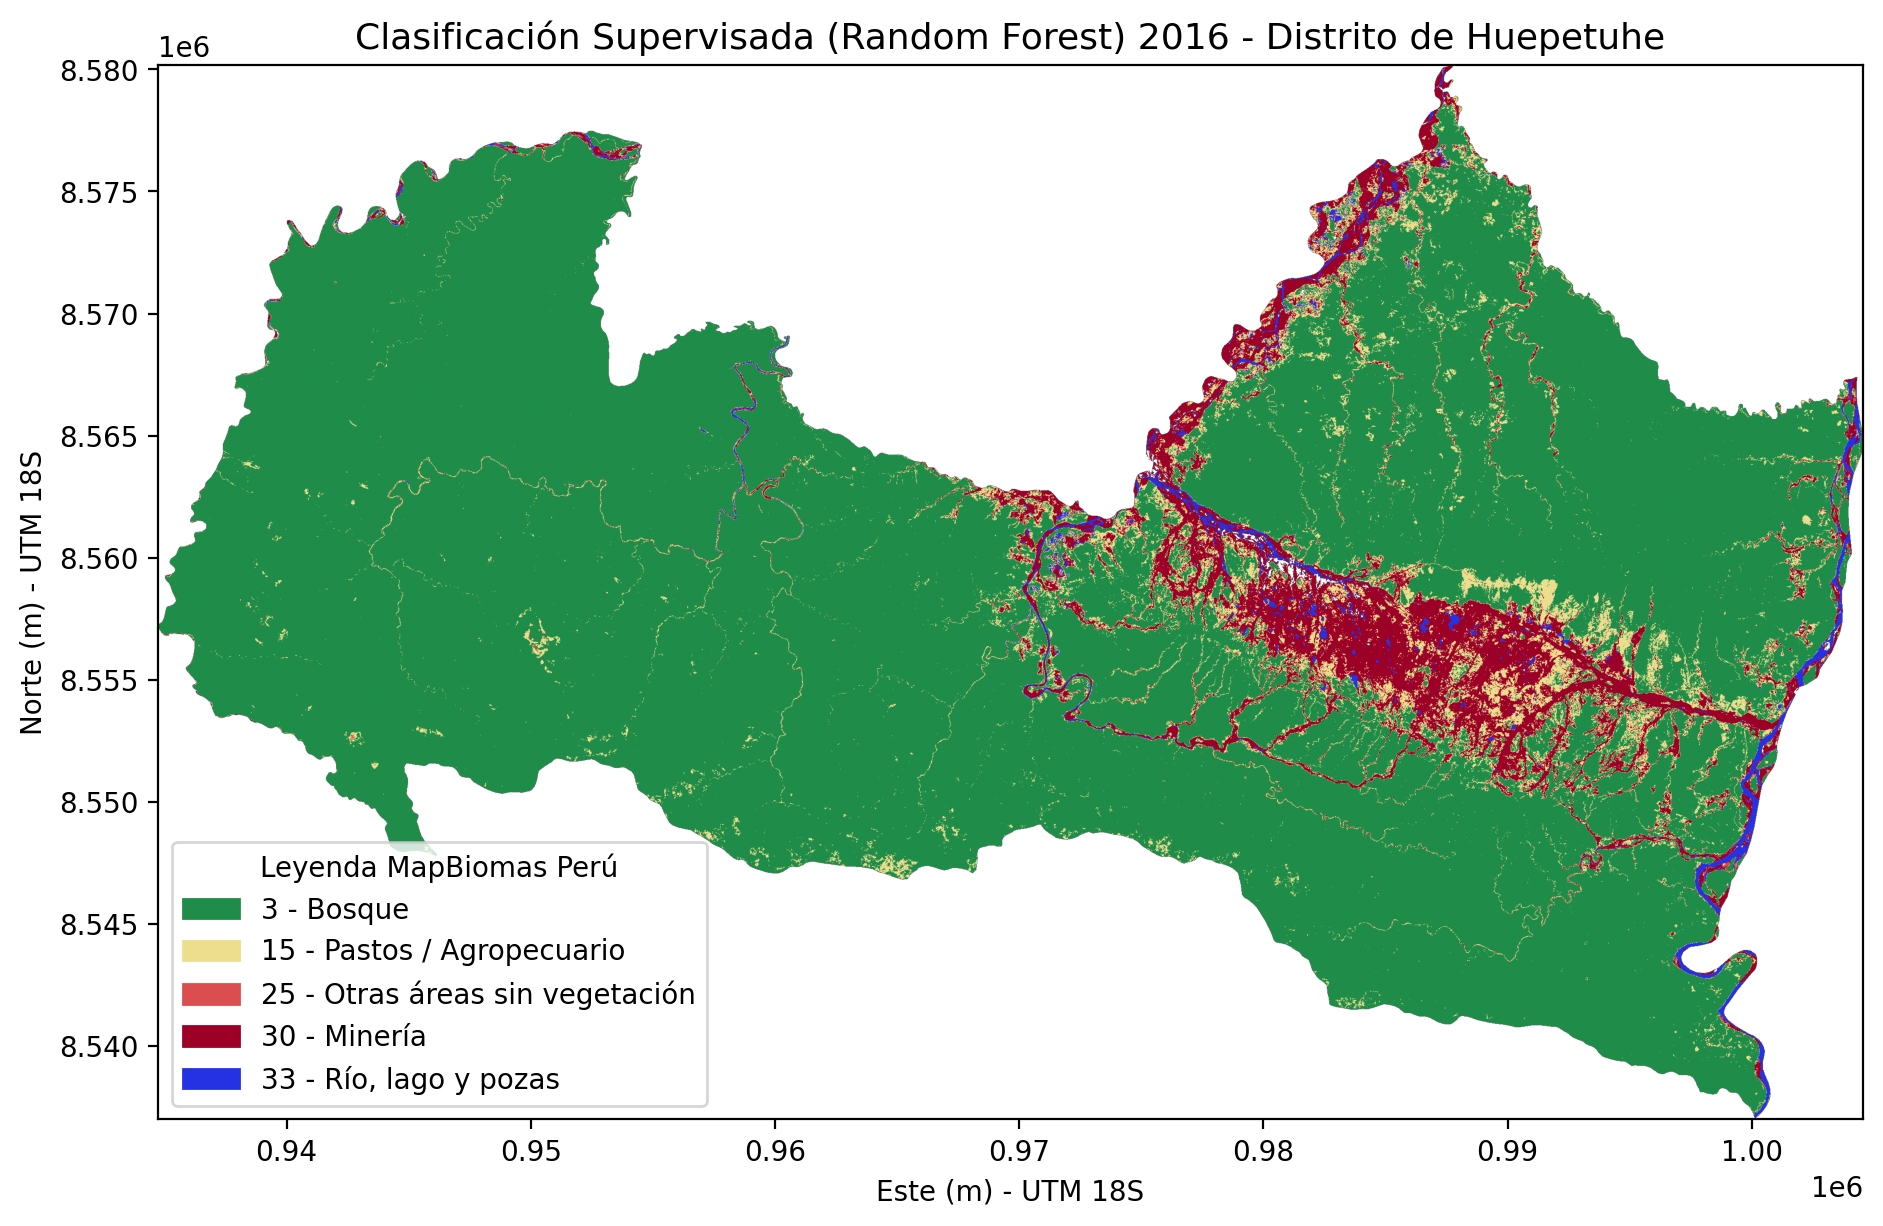

In [ ]:
clases_info = {
    3:  ("3 - Bosque", "#1f8d49"),
    15: ("15 - Pastos / Agropecuario", "#edde8e"),
    18: ("18 - Agricultura", "#e974ed"),
    25: ("25 - Otras áreas sin vegetación", "#db4d4f"),
    30: ("30 - Minería", "#9c0027"),
    33: ("33 - Río, lago y pozas", "#2532e4"),
}

clases_presentes = [c for c in clases_info if np.any(mapa_rf == c)]
colores = [clases_info[c][1] for c in clases_presentes]
cmap_mb = mcolors.ListedColormap(colores)

mapa_indexado = np.full(mapa_rf.shape, np.nan)
for idx, cod in enumerate(clases_presentes):
    mapa_indexado[mapa_rf == cod] = idx

fig, ax = plt.subplots(figsize=(11, 11), dpi=200)
ax.imshow(
    mapa_indexado,
    cmap=cmap_mb,
    extent=[stack.x.min(), stack.x.max(), stack.y.min(), stack.y.max()]
)

parches = [mpatches.Patch(color=clases_info[c][1], label=clases_info[c][0]) for c in clases_presentes]
ax.legend(handles=parches, loc="lower left", title="Leyenda MapBiomas Perú", frameon=True)
ax.set_title("Clasificación Supervisada (Random Forest) 2016 - Distrito de Huepetuhe", fontsize=13)
ax.set_xlabel("Este (m) - UTM 18S")
ax.set_ylabel("Norte (m) - UTM 18S")
plt.savefig("Mapa_RandomForest_Huepetuhe.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show() #graficamos

In [ ]:
# 1. Calcular el área por píxel en hectáreas (asumiendo coordenadas en metros)
res_x = abs(float(stack.x[1] - stack.x[0]))
res_y = abs(float(stack.y[1] - stack.y[0]))
ha_por_pixel = (res_x * res_y) / 10000.0  # 1 ha = 10,000 m²

# 2. Contar píxeles y calcular hectáreas para cada clase presente
etiquetas = [clases_info[c][0] for c in clases_presentes]
hectareas = [np.sum(mapa_rf == c) * ha_por_pixel for c in clases_presentes]
total_ha = sum(hectareas)
porcentajes = [(h / total_ha) * 100 for h in hectareas]

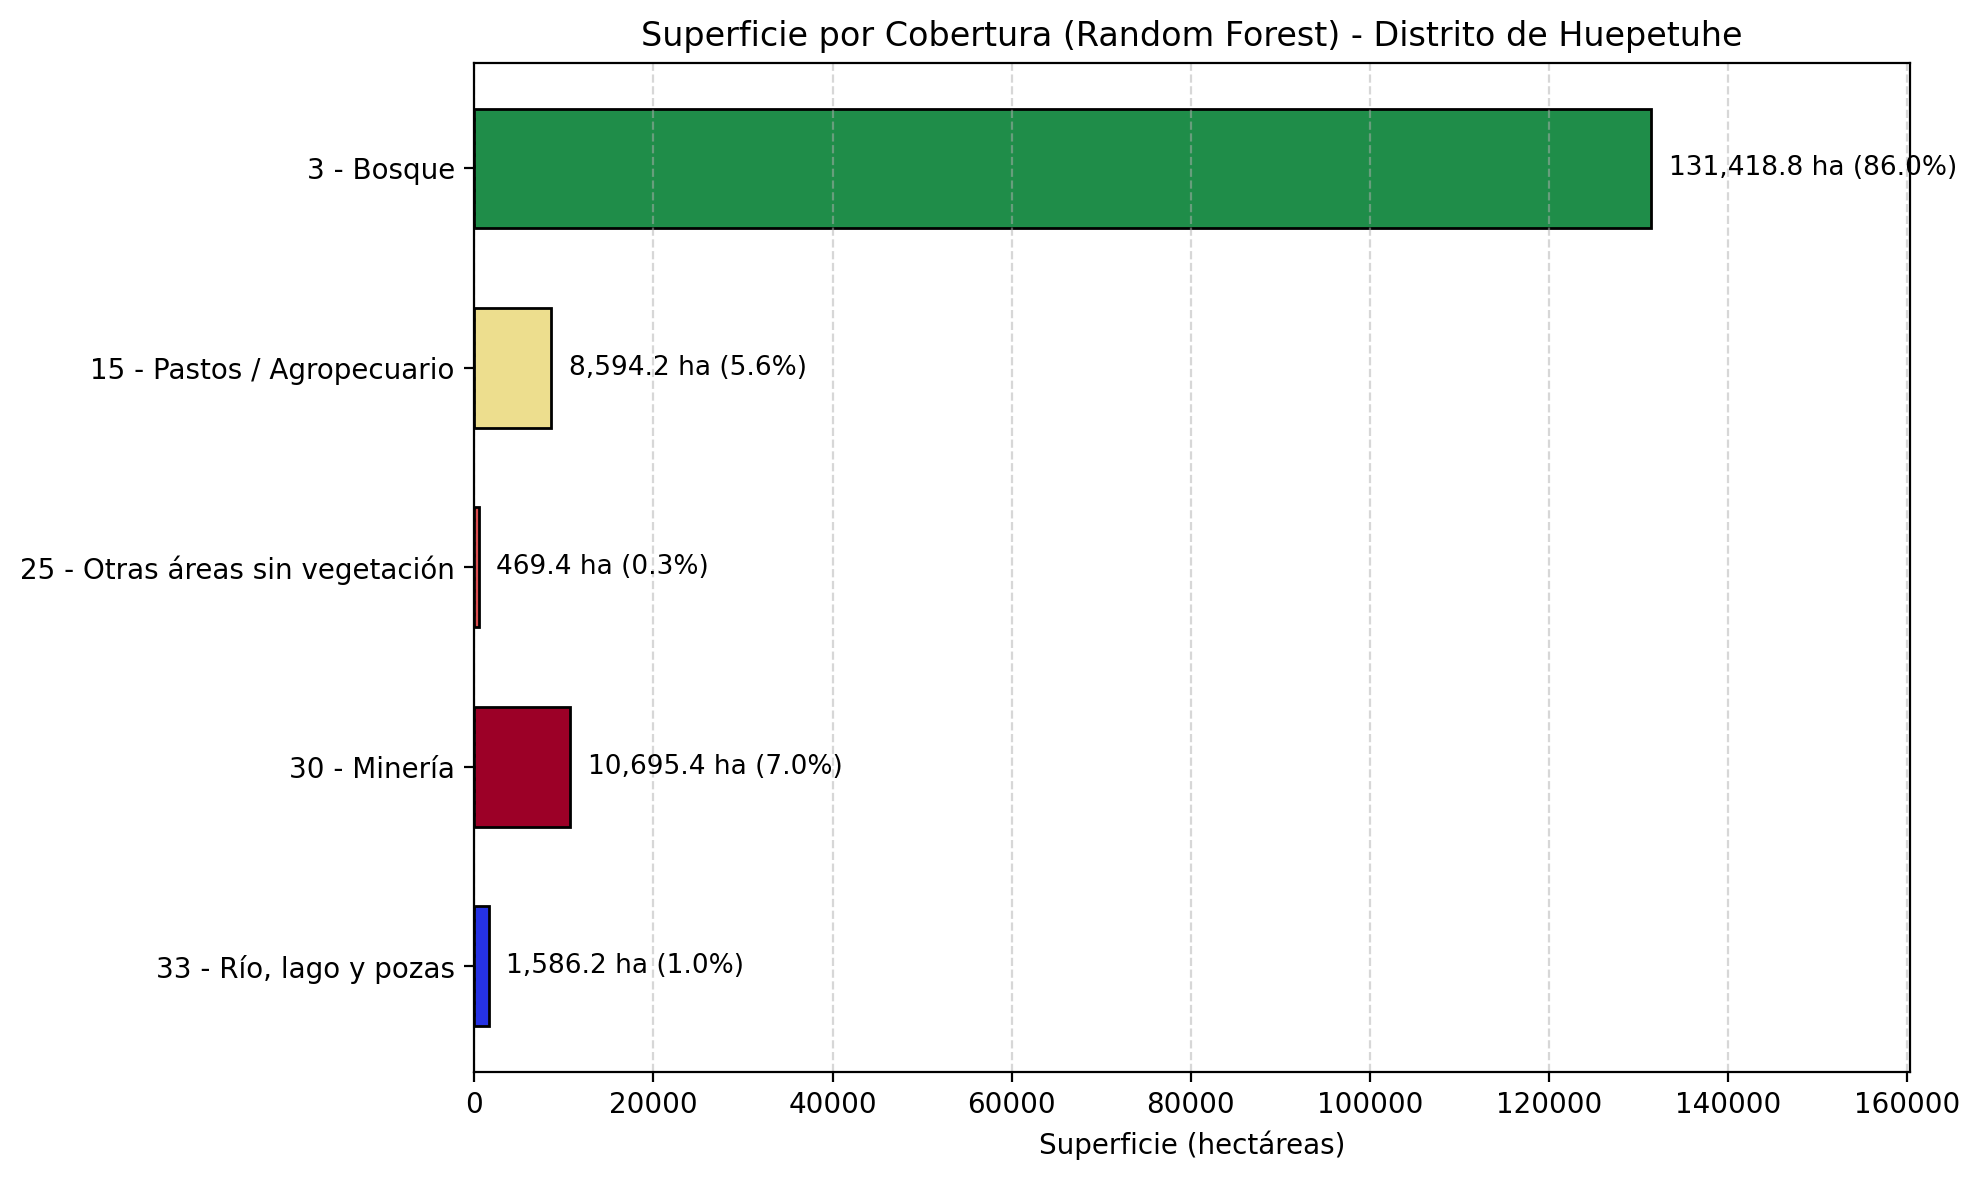

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=200)
barras = ax.barh(etiquetas, hectareas, color=colores, edgecolor="black", height=0.6)

# Añadir etiquetas con el valor en ha y % al lado de cada barra
for barra, ha, pct in zip(barras, hectareas, porcentajes):
    ax.text(
        barra.get_width() + (max(hectareas) * 0.015),
        barra.get_y() + barra.get_height() / 2,
        f"{ha:,.1f} ha ({pct:.1f}%)",
        va="center",
        fontsize=9.5
    )

ax.set_xlim(0, max(hectareas) * 1.22)
ax.invert_yaxis()  # Para que aparezcan en el mismo orden que la leyenda
ax.set_xlabel("Superficie (hectáreas)")
ax.set_title("Superficie por Cobertura (Random Forest) - Distrito de Huepetuhe", fontsize=12)
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("Grafico_Areas_Huepetuhe.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

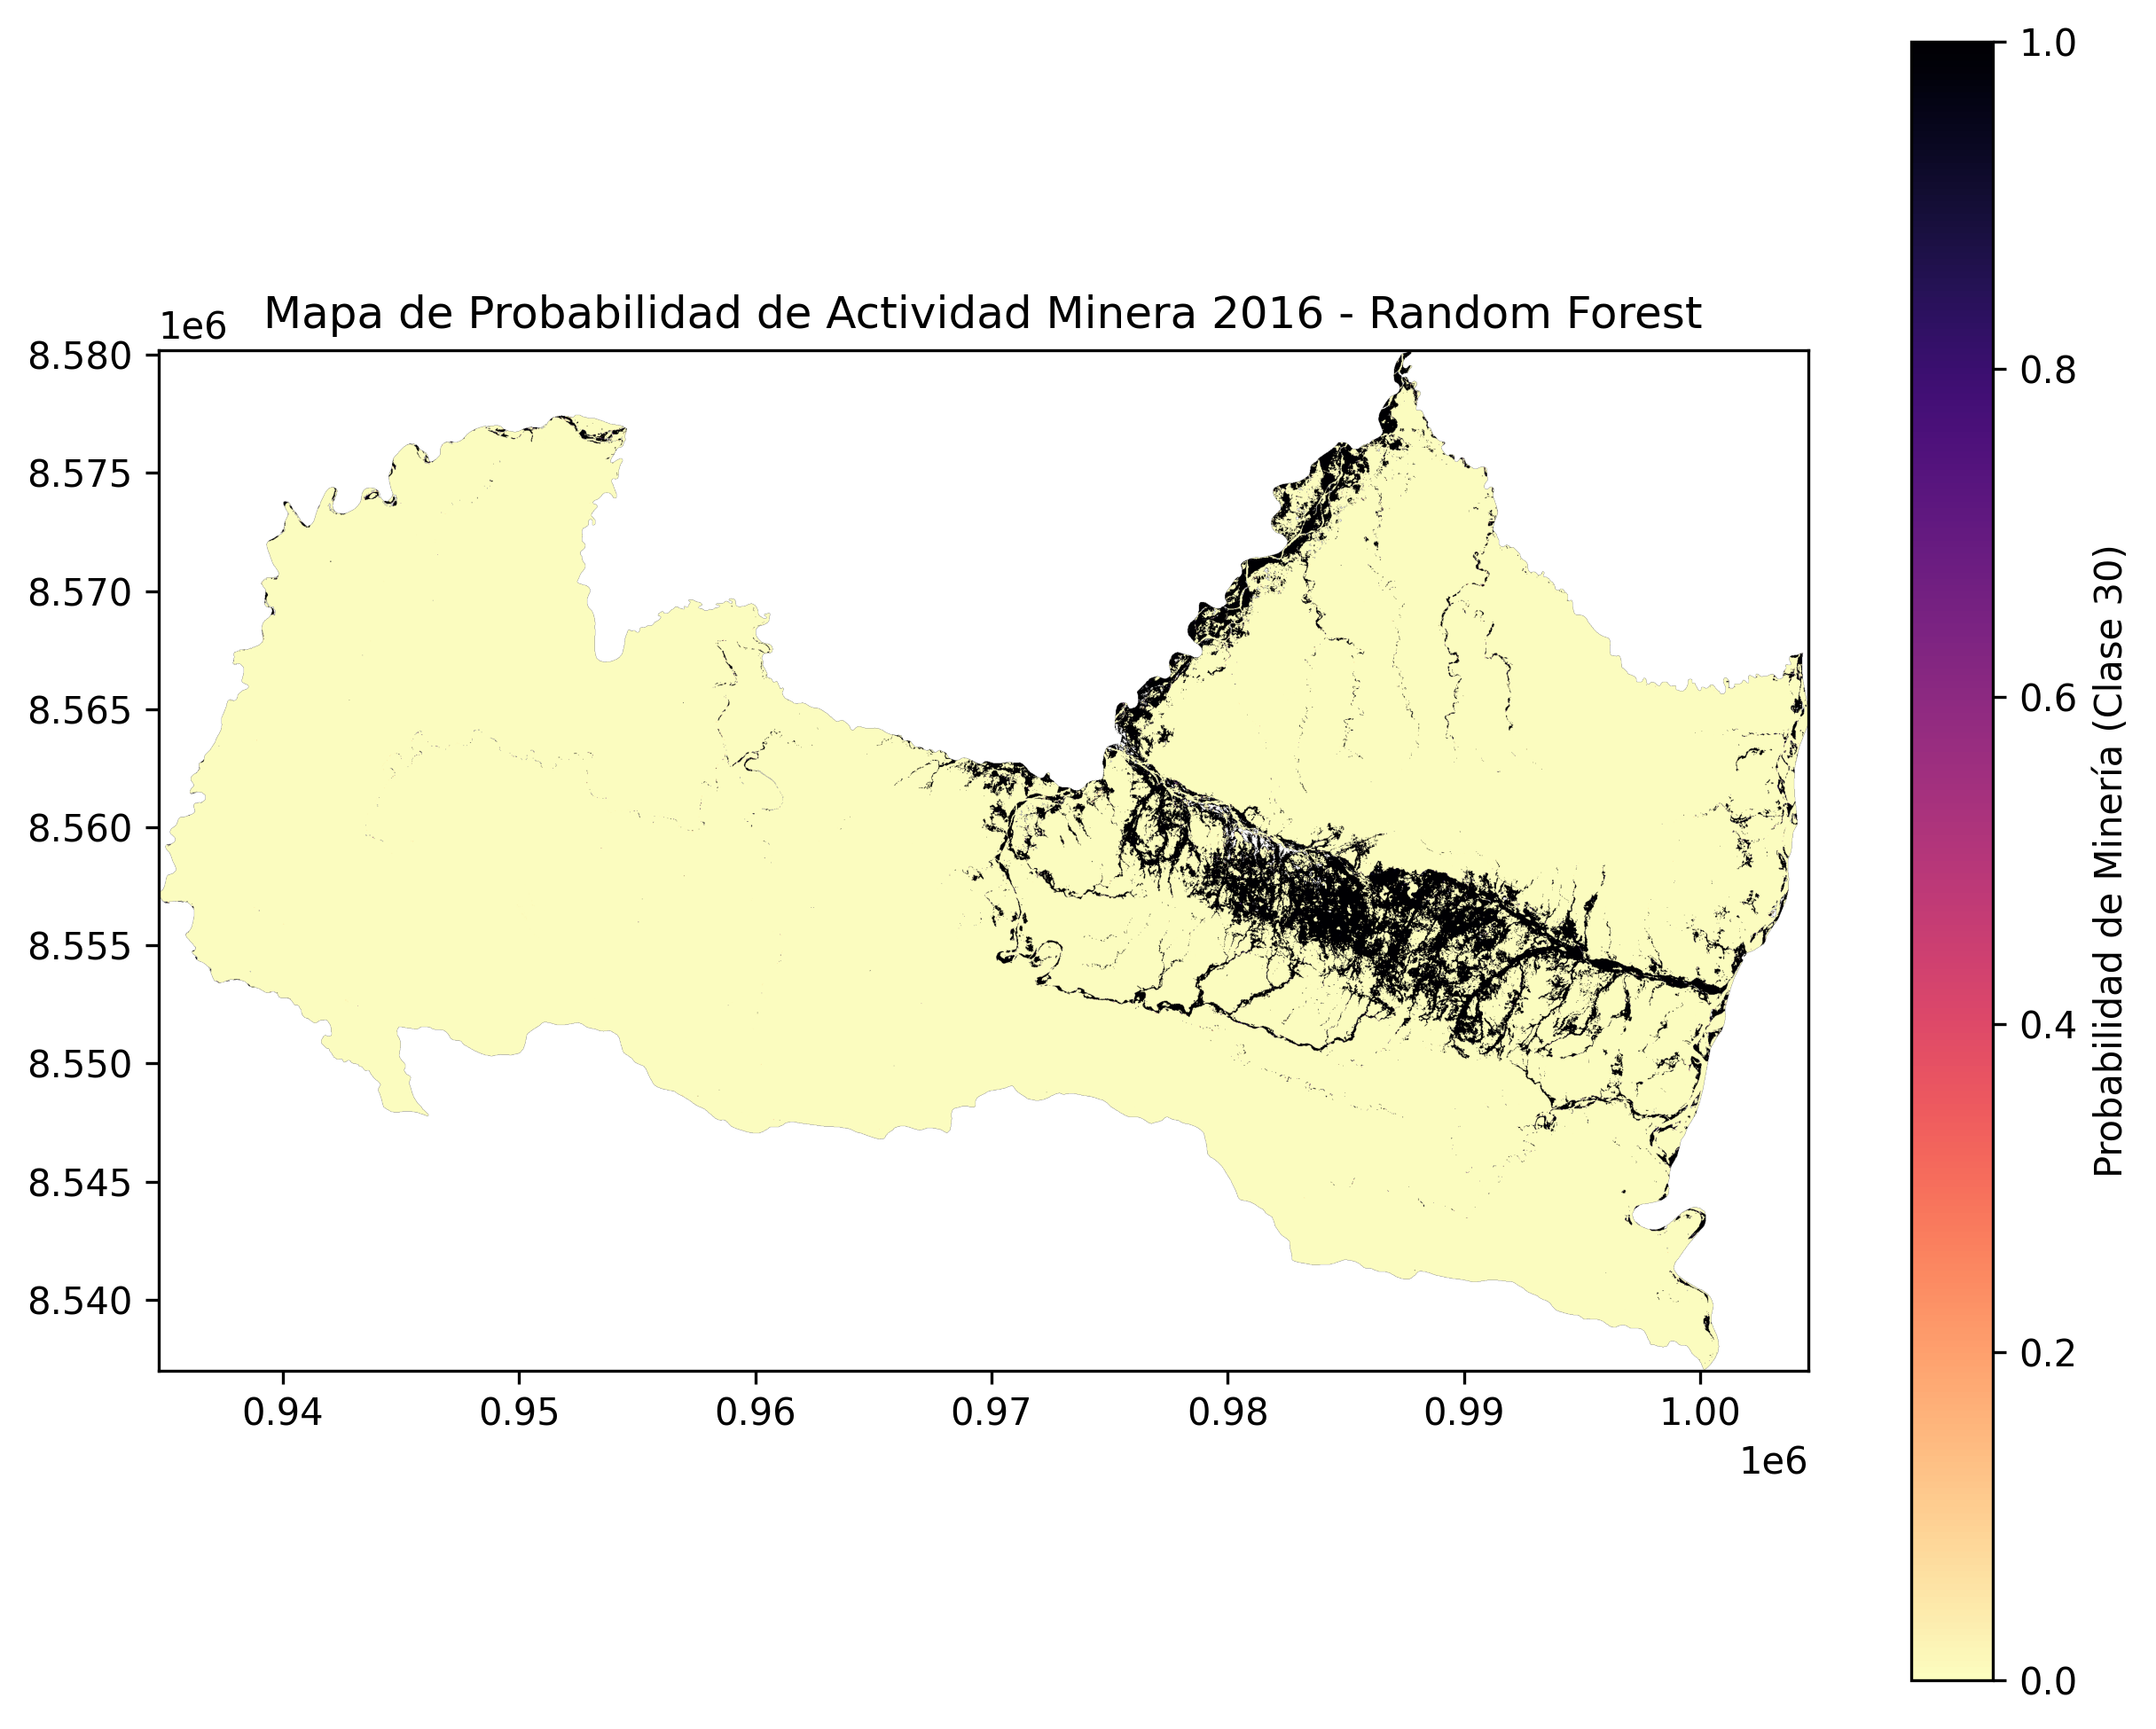

In [ ]:
#mapa de probabilidad de actividad minera a partir de los resultados del entrenamiento del modelo

idx_mineria = list(rf.classes_).index(30)#ubica a minería (codigo 30)
prob_flat = np.full(X_flat.shape[0], np.nan, dtype=np.float32)#calcula probabilidad de datos si es nulo o minero (0-1)
prob_flat[mascara_no_nan] = rf.predict_proba(X_flat[mascara_no_nan])[:, idx_mineria]

mapa_prob_mineria = prob_flat.reshape(n_filas, n_cols)

plt.figure(figsize=(10, 8), dpi=300)
plt.imshow(mapa_prob_mineria, cmap="magma_r", vmin=0, vmax=1,
           extent=[stack.x.min(), stack.x.max(), stack.y.min(), stack.y.max()])
plt.colorbar(label="Probabilidad de Minería (Clase 30)")
plt.title("Mapa de Probabilidad de Actividad Minera 2016 - Random Forest")
plt.savefig("Mapa de Probabilidad de Actividad Minera 2016-Random Forest.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [ ]:
res_x = abs(float(stack.x[1] - stack.x[0]))
res_y = abs(float(stack.y[1] - stack.y[0]))
area_pixel_ha = (res_x * res_y) / 10000.0 #calcula el pixel por área 1 hectarea cuadrada

In [ ]:
rangos = [
    ("Baja (20% - 50%)", (mapa_prob_mineria >= 0.20) & (mapa_prob_mineria < 0.50)),
    (
        "Moderada (50% - 75%)",
        (mapa_prob_mineria >= 0.50) & (mapa_prob_mineria < 0.75),
    ),
    ("Alta (75% - 90%)", (mapa_prob_mineria >= 0.75) & (mapa_prob_mineria < 0.90)),
    ("Muy Alta (90% - 100%)", (mapa_prob_mineria >= 0.90)),
]

etiquetas = [r[0] for r in rangos]
hectareas = [np.sum(r[1]) * area_pixel_ha for r in rangos]
# Colores inspirados en tu paleta magma_r
colores = ["#feb078", "#b73779", "#51127c", "#000004"]

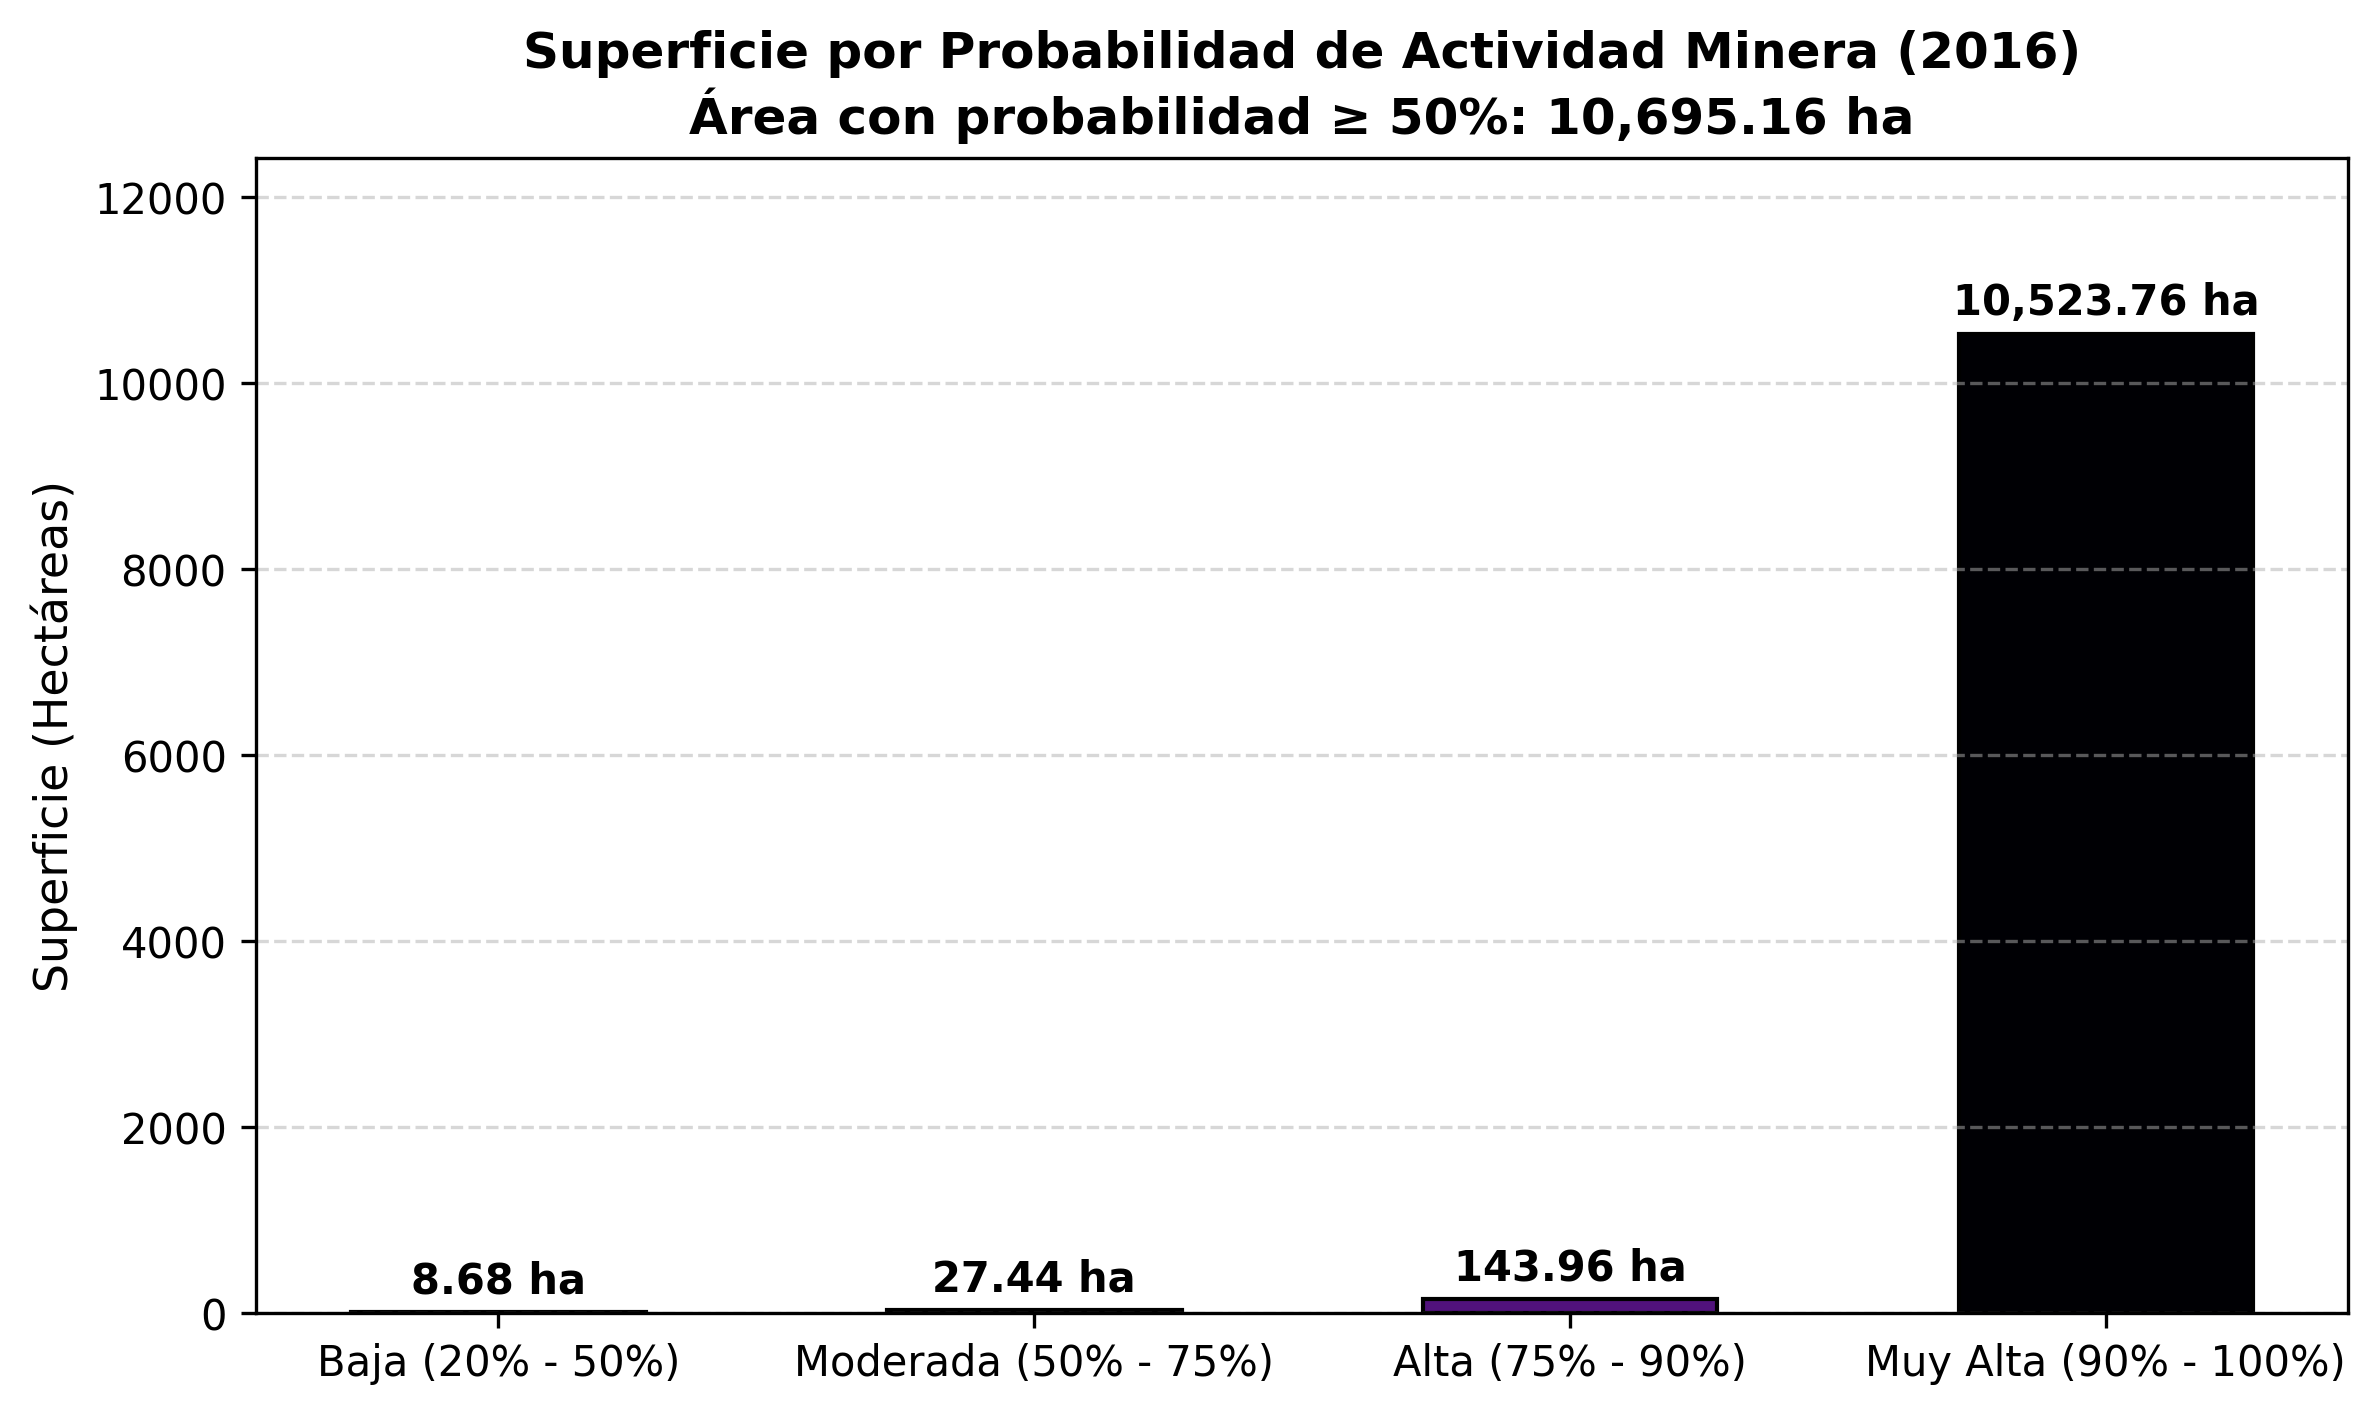

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=300)
barras = ax.bar(
    etiquetas, hectareas, color=colores, edgecolor="black", width=0.55
)

for barra in barras:
  alto = barra.get_height()
  ax.text(
      barra.get_x() + barra.get_width() / 2,
      alto + (max(hectareas) * 0.02),
      f"{alto:,.2f} ha",
      ha="center",
      fontsize=10,
      fontweight="bold",
  )

# Calcular el total con probabilidad >= 50% (umbral estándar de clasificación)
total_probable = sum(hectareas[1:])

ax.set_ylim(0, max(hectareas) * 1.18)
ax.set_ylabel("Superficie (Hectáreas)", fontsize=11)
ax.set_title(
    "Superficie por Probabilidad de Actividad Minera (2016)\nÁrea con"
    f" probabilidad ≥ 50%: {total_probable:,.2f} ha",
    fontsize=12,
    fontweight="bold",
)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.savefig(
    "Hectareas_Probabilidad_Mineria_2016.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

C. Cuantificación por cuadriculas

In [ ]:
n_grid_filas = 6      # Cantidad de divisiones verticales (A, B, C...)
n_grid_cols = 6       # Cantidad de divisiones horizontales (1, 2, 3...)
umbral_prob = 0.5     # Probabilidad mínima para considerar un píxel como minería

In [ ]:
res_x = abs(float(stack.x[1] - stack.x[0]))
res_y = abs(float(stack.y[1] - stack.y[0]))
ha_por_pixel = (res_x * res_y) / 10000.0

In [ ]:
#determina los limites geograficos
xmin, xmax = float(stack.x.min()), float(stack.x.max())
ymin, ymax = float(stack.y.min()), float(stack.y.max())

In [ ]:
indices_filas = np.array_split(np.arange(n_filas), n_grid_filas)
indices_cols = np.array_split(np.arange(n_cols), n_grid_cols) #divide en filas y columnas

resultados = []
letras = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"#la combinación de letras que tendran las cuadriculas como nombre

for i, filas_idx in enumerate(indices_filas):
    for j, cols_idx in enumerate(indices_cols):
        # Extraer submatriz de la cuadrícula
        submapa = mapa_prob_mineria[np.ix_(filas_idx, cols_idx)]

        # Contar píxeles válidos y píxeles con alta probabilidad de minería
        validos = ~np.isnan(submapa)
        pixeles_mineria = int(np.sum(submapa[validos] >= umbral_prob))
        prob_media = float(np.nanmean(submapa)) if np.any(validos) else 0.0

        # Coordenadas de la celda para dibujarla en el mapa
        x0 = xmin + (cols_idx[0] / n_cols) * (xmax - xmin)
        x1 = xmin + ((cols_idx[-1] + 1) / n_cols) * (xmax - xmin)
        # Nota: en imágenes, la fila 0 está arriba (ymax)
        y1 = ymax - (filas_idx[0] / n_filas) * (ymax - ymin)
        y0 = ymax - ((filas_idx[-1] + 1) / n_filas) * (ymax - ymin)

        resultados.append({
            "Cuadricula": f"{letras[i]}{j+1}",
            "Pixeles_Mineria": pixeles_mineria,
            "Area_Mineria_ha": round(pixeles_mineria * ha_por_pixel, 2),
            "Prob_Media": round(prob_media, 3),
            "bounds": (x0, y0, x1 - x0, y1 - y0),
            "centro": ((x0 + x1) / 2, (y0 + y1) / 2)
        })

In [ ]:
import pandas as pd
import matplotlib.patches as patches

df_ranking = pd.DataFrame(resultados).sort_values(
    by="Pixeles_Mineria", ascending=False
).reset_index(drop=True)

print("Top 10 cuadrículas con mayor probabilidad de minería:")
print(df_ranking[["Cuadricula", "Pixeles_Mineria", "Area_Mineria_ha", "Prob_Media"]].head(10))

Top 10 cuadrículas con mayor probabilidad de minería:
  Cuadricula  Pixeles_Mineria  Area_Mineria_ha  Prob_Media
0         D5           104485          4179.40       0.499
1         C4            39635          1585.40       0.252
2         D6            26804          1072.16       0.157
3         D4            24813           992.52       0.118
4         A5            16943           677.72       0.227
5         B4            12452           498.08       0.360
6         E6             9328           373.12       0.077
7         B5             8112           324.48       0.040
8         C5             6729           269.16       0.032
9         E5             4984           199.36       0.024


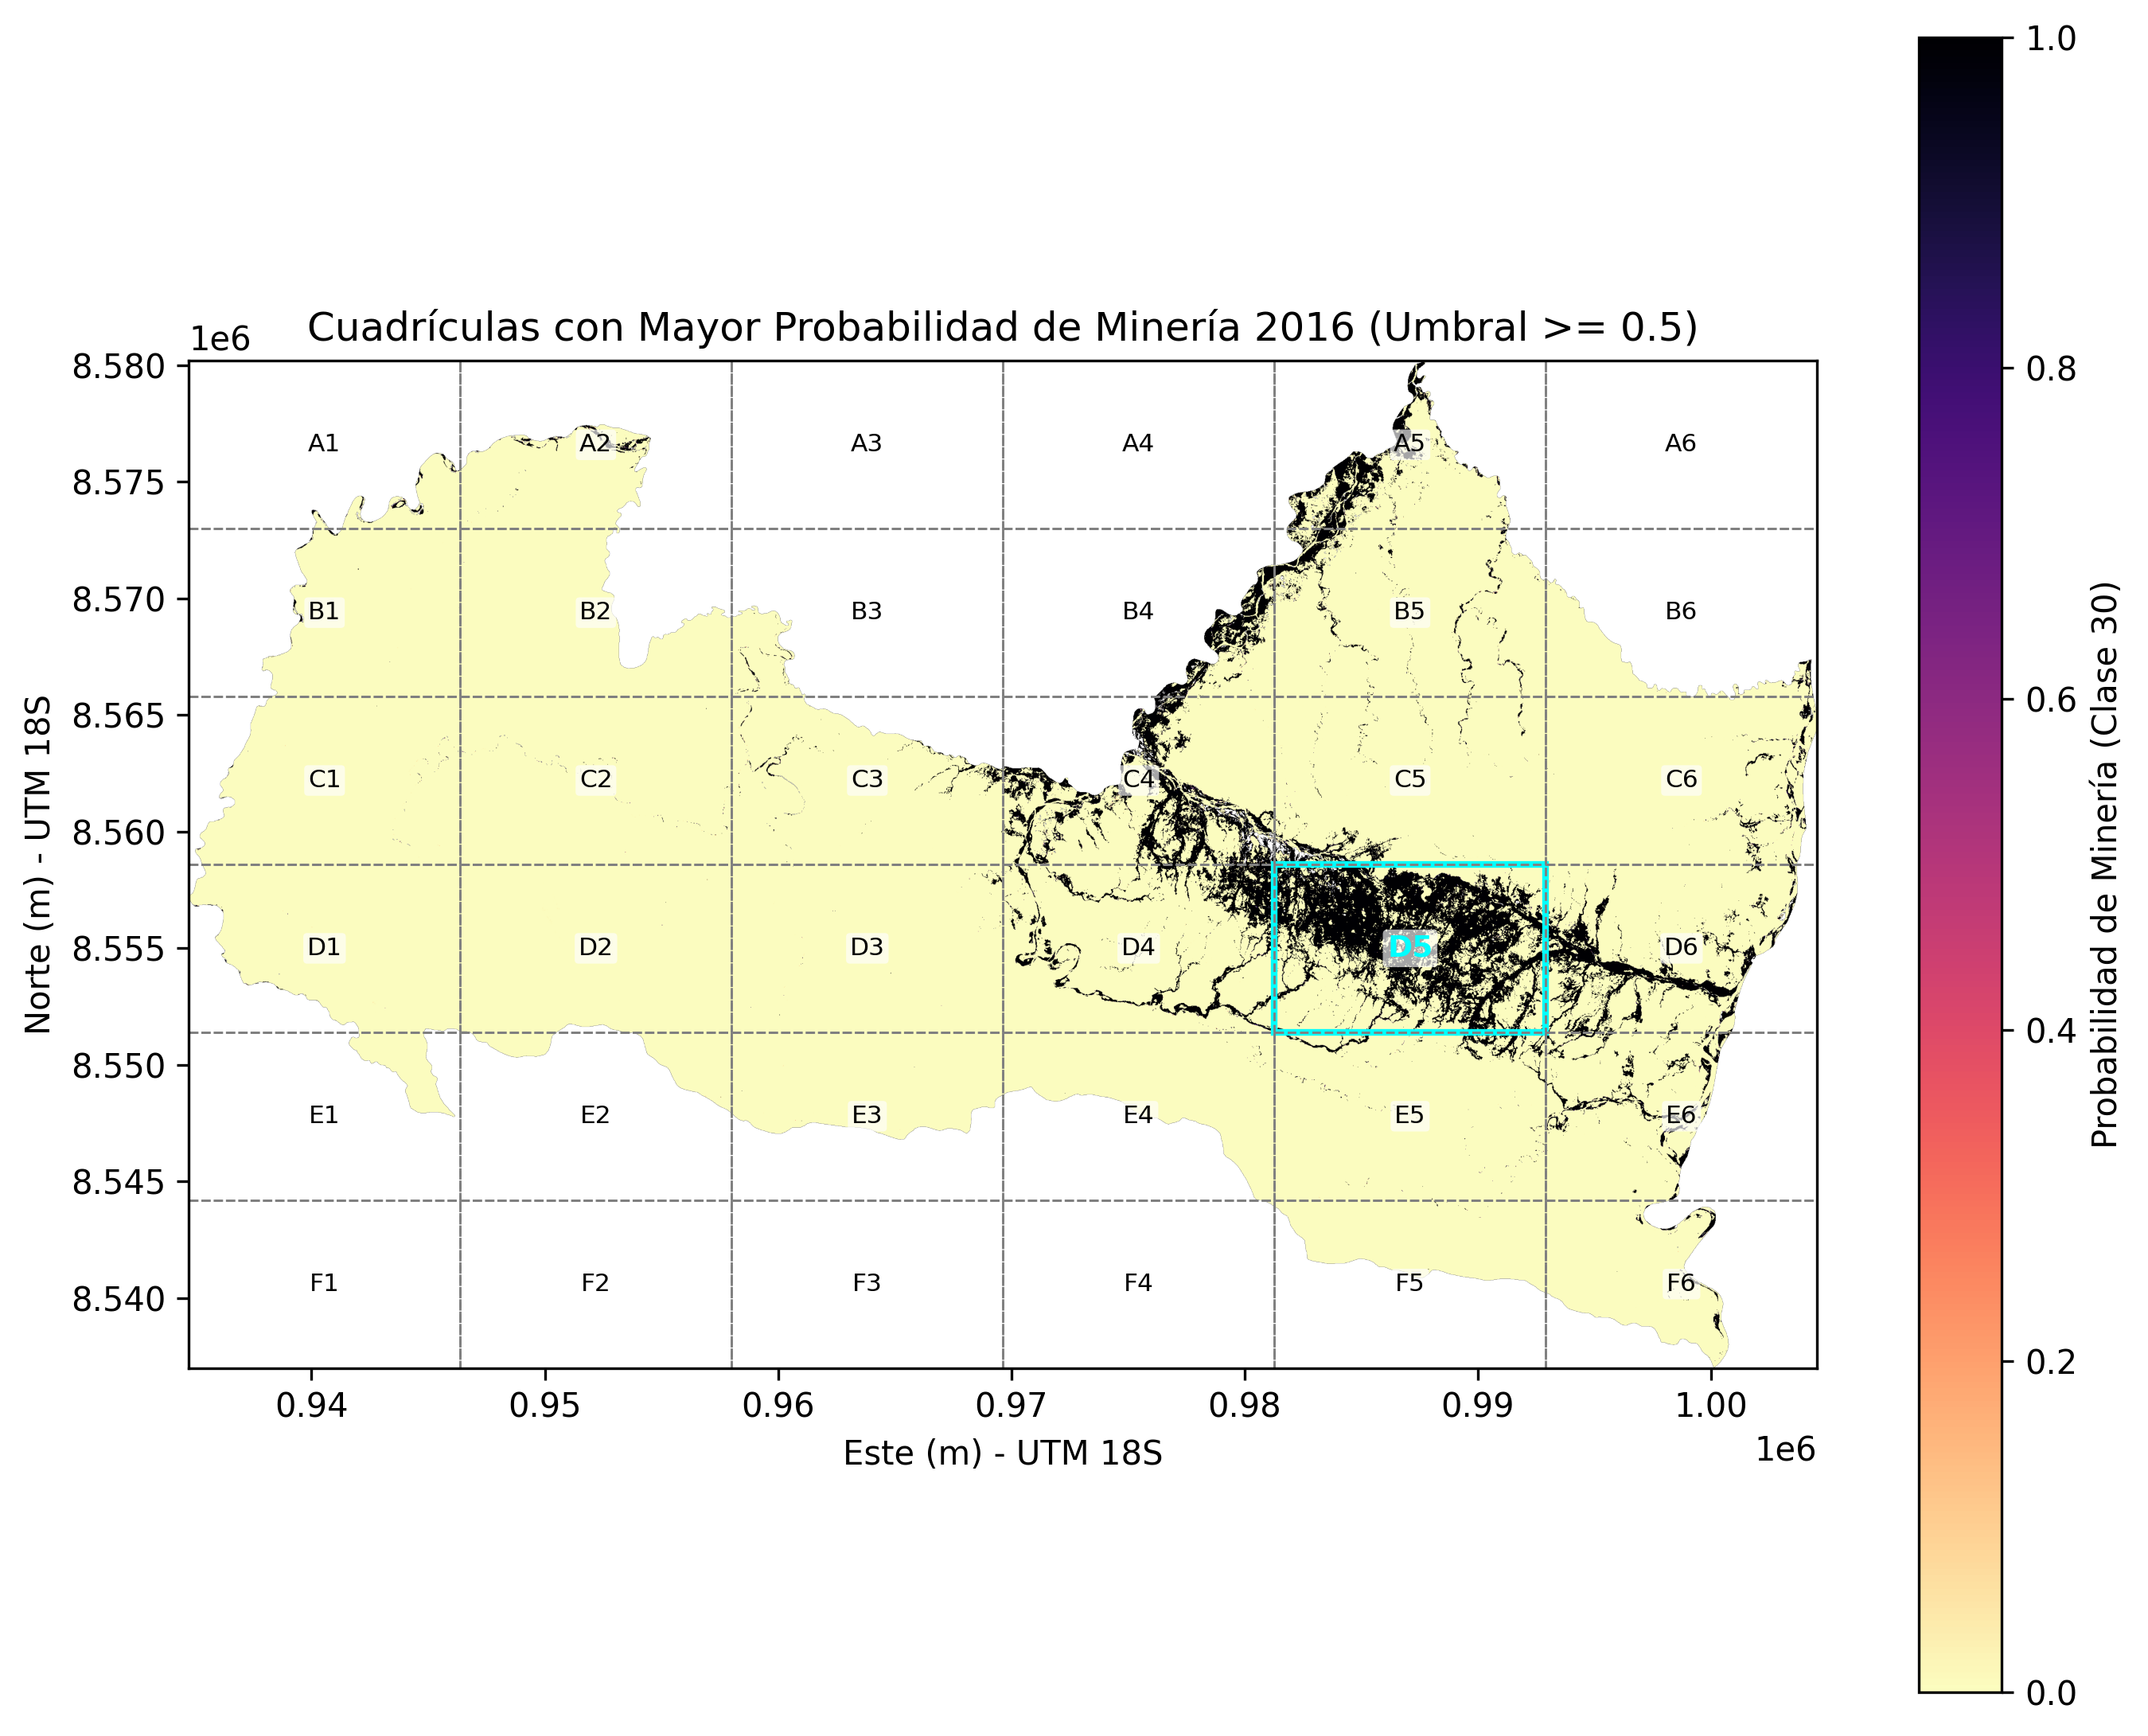

In [ ]:
fig, ax = plt.subplots(figsize=(11, 9), dpi=300)
im = ax.imshow(
    mapa_prob_mineria, cmap="magma_r", vmin=0, vmax=1,
    extent=[xmin, xmax, ymin, ymax]
)
plt.colorbar(im, ax=ax, label="Probabilidad de Minería (Clase 30)")

top_1_ids = set(df_ranking["Cuadricula"].head(1)) #este se puede modificar para obtener mas que el top 1, por ejemplo top3 o top5 con cantidad minera

for _, row in df_ranking.iterrows():
    x0, y0, ancho, alto = row["bounds"]
    cx, cy = row["centro"]
    es_top = row["Cuadricula"] in top_1_ids

    # Dibujar borde de la cuadrícula (en cian grueso si está en el Top 5)
    rect = patches.Rectangle(
        (x0, y0), ancho, alto,
        linewidth=2.0 if es_top else 0.7,
        edgecolor="#00ffff" if es_top else "gray",
        facecolor="none",
        linestyle="-" if es_top else "--"
    )
    ax.add_patch(rect)

    # Etiqueta con el código de cuadrícula
    ax.text(
        cx, cy, row["Cuadricula"],
        color="#00ffff" if es_top else "black",
        fontsize=9 if es_top else 7.5,
        fontweight="bold" if es_top else "normal",
        ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.15", facecolor="white", alpha=0.65, edgecolor="none")
    )

ax.set_title(f"Cuadrículas con Mayor Probabilidad de Minería 2016 (Umbral >= {umbral_prob})", fontsize=12)
ax.set_xlabel("Este (m) - UTM 18S")
ax.set_ylabel("Norte (m) - UTM 18S")
plt.savefig("Cuadricula_alta_Probabilidad_Mineria.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [ ]:
top1 = df_ranking.iloc[0] #reconoce cuadricula lider
id_top1 = top1["Cuadricula"]

In [ ]:
letras = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
fila_idx = letras.index(id_top1[0])
col_idx = int(id_top1[1:]) - 1

submapa_rf = mapa_rf[np.ix_(indices_filas[fila_idx], indices_cols[col_idx])]#solo los pixeles de la cuadricula
validos_celda = ~np.isnan(submapa_rf)
total_pixeles_validos = int(np.sum(validos_celda))

print(f"=== COMPOSICIÓN DE COBERTURAS EN LA CUADRÍCULA {id_top1} ===")
desglose_top1 = []
for cod, (nombre, color) in clases_info.items():
    pix_clase = int(np.sum(submapa_rf[validos_celda] == cod))
    pct_clase = (pix_clase / total_pixeles_validos * 100) if total_pixeles_validos > 0 else 0.0
    ha_clase = pix_clase * ha_por_pixel
    desglose_top1.append({
        "Clase": nombre,
        "Pixeles": pix_clase,
        "Area_ha": round(ha_clase, 2),
        "Porcentaje (%)": round(pct_clase, 2)
    })#desglose por cobertura

df_composicion_top1 = pd.DataFrame(desglose_top1).sort_values(by="Porcentaje (%)", ascending=False)#hace la tabla
print(df_composicion_top1.to_string(index=False))

=== COMPOSICIÓN DE COBERTURAS EN LA CUADRÍCULA D5 ===
                          Clase  Pixeles  Area_ha  Porcentaje (%)
                   30 - Minería   104486  4179.44           49.87
                     3 - Bosque    54276  2171.04           25.90
     15 - Pastos / Agropecuario    45047  1801.88           21.50
         33 - Río, lago y pozas     4540   181.60            2.17
25 - Otras áreas sin vegetación      561    22.44            0.27
               18 - Agricultura        0     0.00            0.00


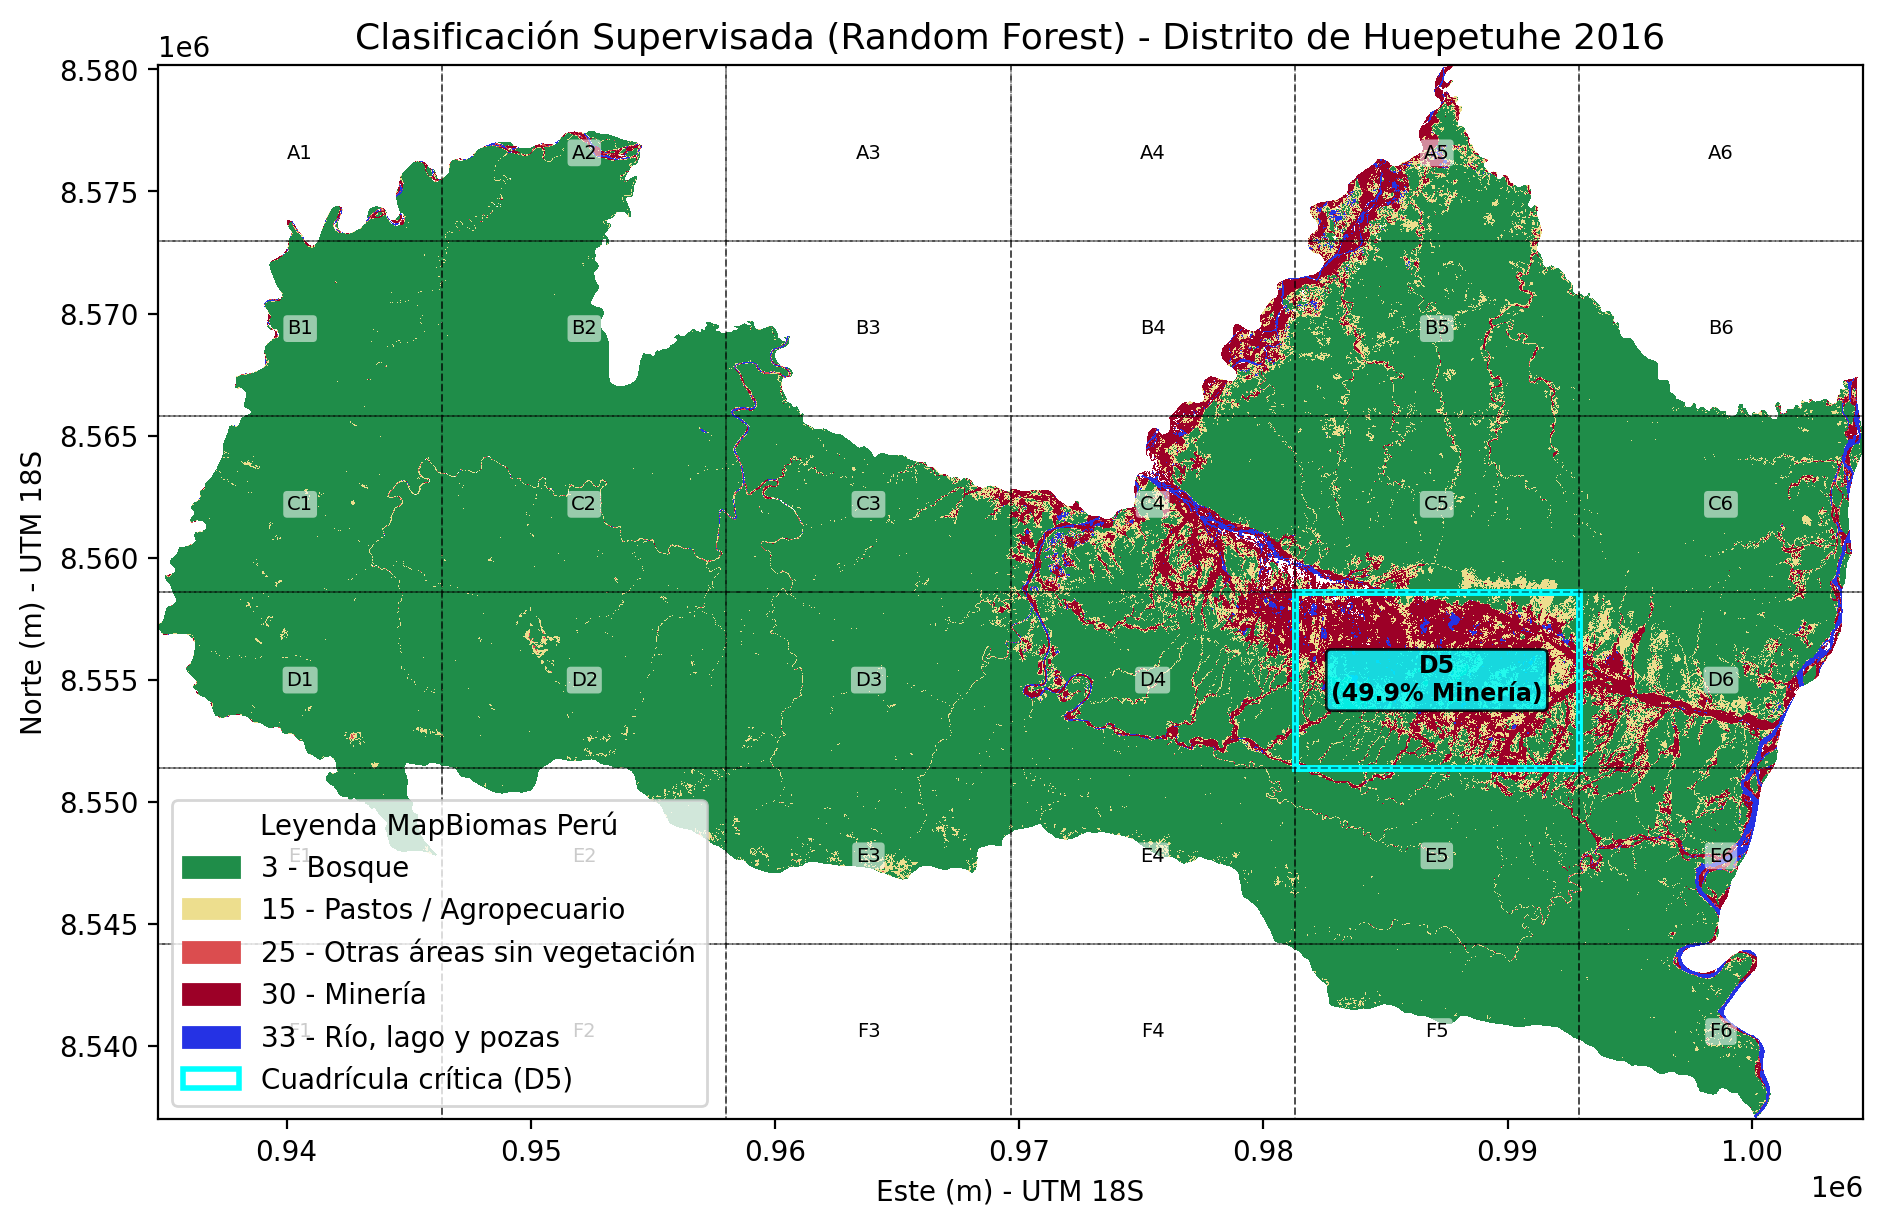

In [ ]:
#agrega las cuadriculas destaca la cuadricula top1
fig, ax = plt.subplots(figsize=(11, 11), dpi=200)
ax.imshow(
    mapa_indexado,
    cmap=cmap_mb,
    interpolation="nearest",
    extent=[stack.x.min(), stack.x.max(), stack.y.min(), stack.y.max()]
)

for _, row in df_ranking.iterrows():
    x0, y0, ancho, alto = row["bounds"]
    cx, cy = row["centro"]
    es_top1 = (row["Cuadricula"] == id_top1)

    rect = mpatches.Rectangle(
        (x0, y0), ancho, alto,
        linewidth=2.5 if es_top1 else 0.7,
        edgecolor="#00ffff" if es_top1 else "black",
        facecolor="none",
        linestyle="-" if es_top1 else "--",
        alpha=1.0 if es_top1 else 0.45
    )
    ax.add_patch(rect)

    # Mostrar código y % de minería en la celda ganadora; solo código en las demás
    pct_min_celda = df_composicion_top1.loc[
        df_composicion_top1["Clase"] == clases_info[30][0], "Porcentaje (%)"
    ].values[0]

    etiqueta = f"{row['Cuadricula']}\n({pct_min_celda:.1f}% Minería)" if es_top1 else row["Cuadricula"]

    ax.text(
        cx, cy, etiqueta,
        color="black",
        fontsize=8.5 if es_top1 else 7,
        fontweight="bold" if es_top1 else "normal",
        ha="center", va="center",
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="#00ffff" if es_top1 else "white",
            alpha=0.85 if es_top1 else 0.55,
            edgecolor="black" if es_top1 else "none"
        )
    )

# Leyenda con las coberturas de MapBiomas + el recuadro de la cuadrícula crítica
parches = [mpatches.Patch(color=clases_info[c][1], label=clases_info[c][0]) for c in clases_presentes]
parches.append(mpatches.Patch(facecolor="none", edgecolor="#00ffff", linewidth=2, label=f"Cuadrícula crítica ({id_top1})"))

ax.legend(handles=parches, loc="lower left", title="Leyenda MapBiomas Perú", frameon=True)
ax.set_title("Clasificación Supervisada (Random Forest) - Distrito de Huepetuhe 2016", fontsize=13)
ax.set_xlabel("Este (m) - UTM 18S")
ax.set_ylabel("Norte (m) - UTM 18S")
plt.savefig("Mapa_RandomForest_Huepetuhe_Cuadricula.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [ ]:
# --- 1. EXTRAER LOS DATOS Y COORDENADAS EXACTAS DE LA CUADRÍCULA #1 ---
top1 = df_ranking.iloc[0]
id_top1 = top1["Cuadricula"]
x0, y0, ancho, alto = top1["bounds"]
x1, y1 = x0 + ancho, y0 + alto

letras = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
fila_idx = letras.index(id_top1[0])
col_idx = int(id_top1[1:]) - 1

# Recortar tanto el mapa indexado (para graficar) como el original (para calcular %)
submapa_indexado = mapa_indexado[np.ix_(indices_filas[fila_idx], indices_cols[col_idx])]
submapa_rf = mapa_rf[np.ix_(indices_filas[fila_idx], indices_cols[col_idx])]

# --- 2. PREPARAR LEYENDA CON LAS COBERTURAS PRESENTES EN ESTA CUADRÍCULA ---
validos_celda = ~np.isnan(submapa_rf)
total_validos = int(np.sum(validos_celda))

parches_celda = []
for cod in clases_presentes:
    pix_clase = int(np.sum(submapa_rf[validos_celda] == cod))
    if pix_clase > 0:  # Solo mostrar en la leyenda las clases que existen dentro de esta celda
        pct = (pix_clase / total_validos) * 100
        nombre_clase, color_clase = clases_info[cod]
        parches_celda.append(
            mpatches.Patch(color=color_clase, label=f"{nombre_clase} ({pct:.1f}%)")
        )

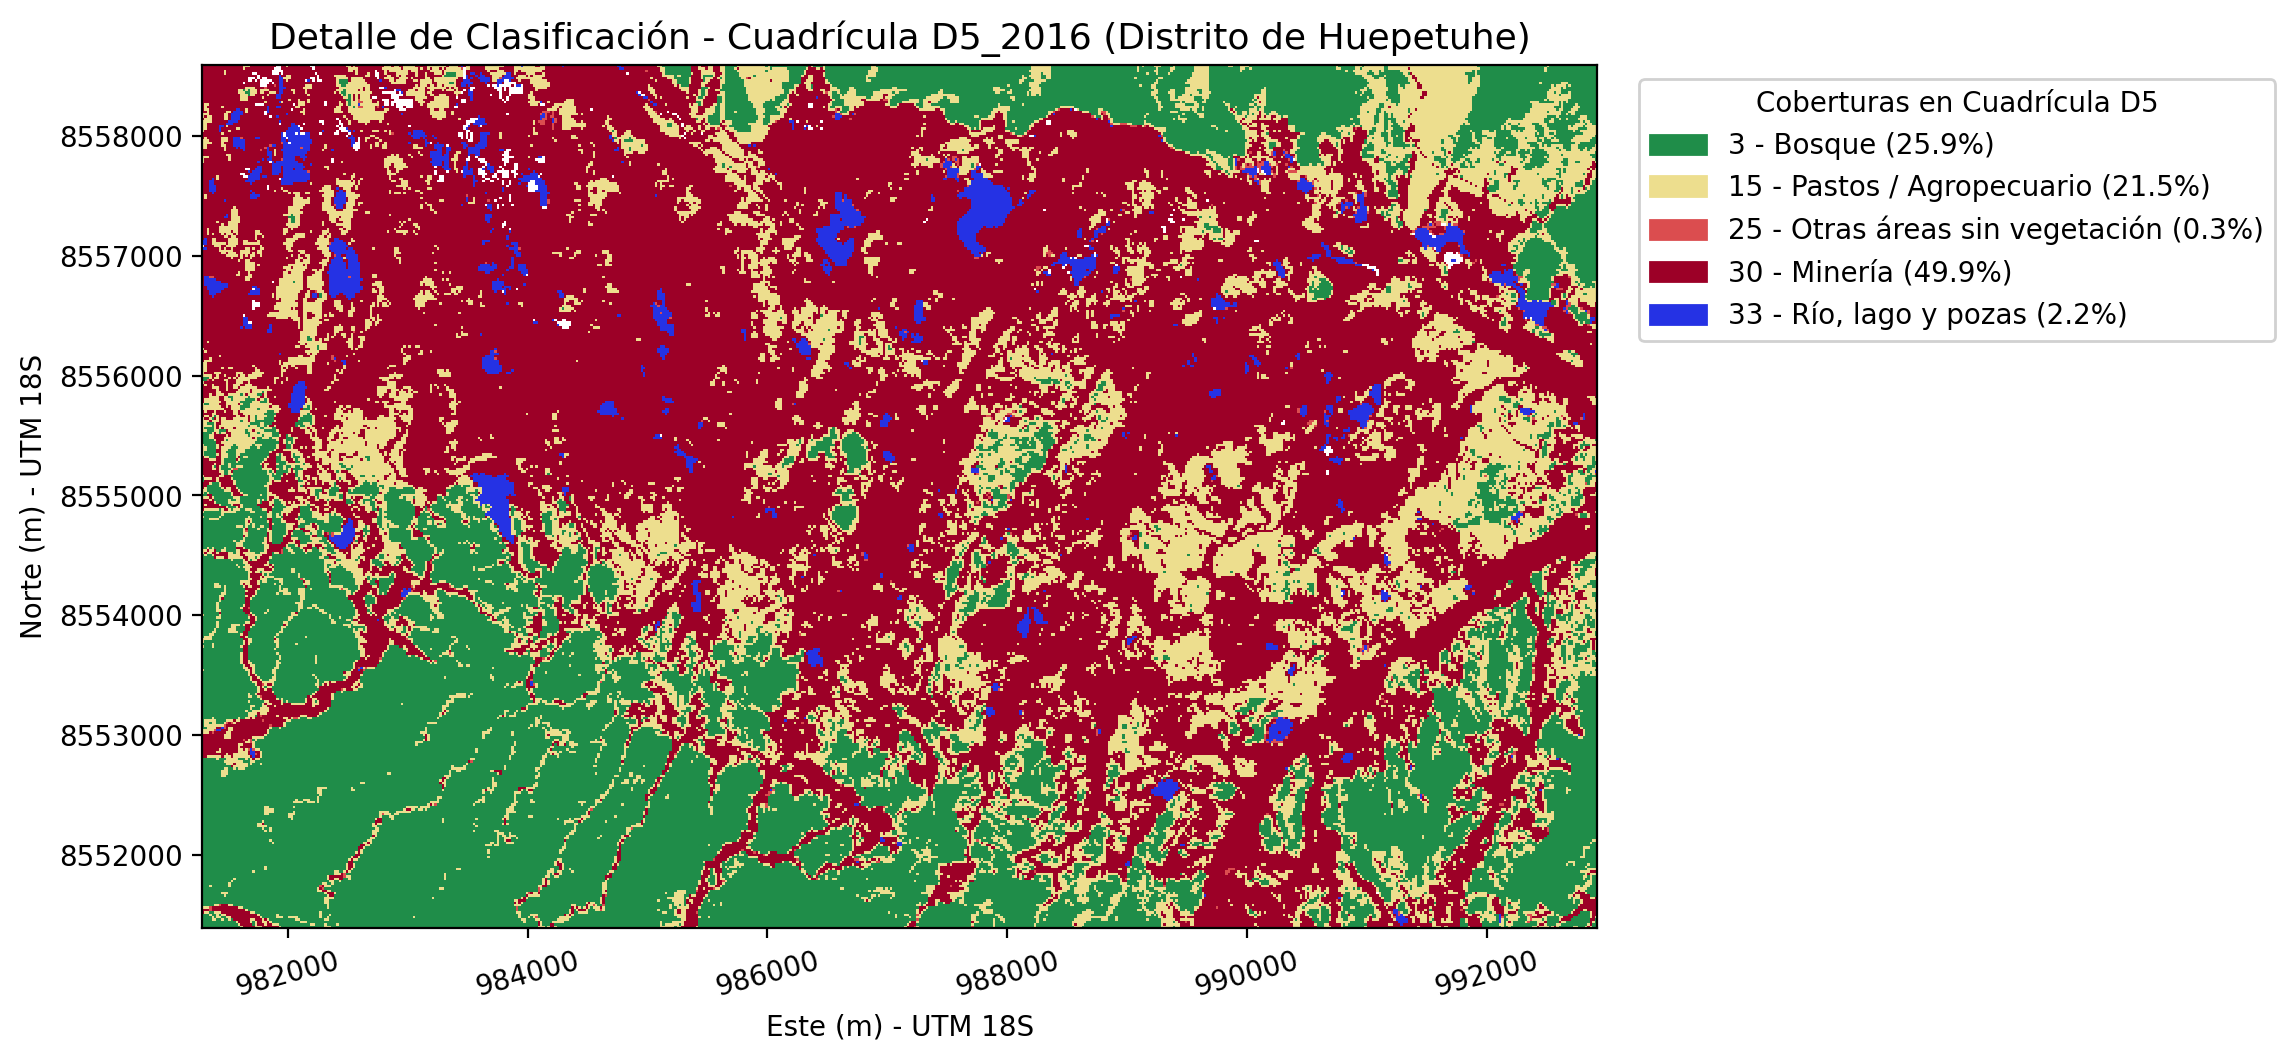

In [ ]:

# --- 3. GRAFICAR EL MAPA EXCLUSIVO DE LA CUADRÍCULA ---
fig, ax = plt.subplots(figsize=(9, 9), dpi=200)

ax.imshow(
    submapa_indexado,
    cmap=cmap_mb,
    vmin=0,
    vmax=len(clases_presentes) - 1,  # Evita que cambien los colores si falta alguna clase en el recorte
    interpolation="nearest",
    extent=[x0, x1, y0, y1]
)

ax.legend(
    handles=parches_celda,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    title=f"Coberturas en Cuadrícula {id_top1}",
    frameon=True,
    facecolor="white",
    framealpha=0.9
)

ax.set_title(f"Detalle de Clasificación - Cuadrícula {id_top1}_2016 (Distrito de Huepetuhe)", fontsize=13)
ax.set_xlabel("Este (m) - UTM 18S")
ax.set_ylabel("Norte (m) - UTM 18S")

# Evitar notación científica en los ejes si las coordenadas se ven apretadas
ax.ticklabel_format(useOffset=False, style="plain")
plt.xticks(rotation=15)

plt.savefig(f"Detalle_Cuadricula_{id_top1}_2016_Huepetuhe.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [ ]:
filas, cols = submapa_rf.shape
area_pixel_ha = ((ancho / cols) * (alto / filas)) / 10000.0

datos_tabla = []

for cod in clases_presentes:
    pix_clase = int(np.sum(submapa_rf[validos_celda] == cod))
    if pix_clase > 0:  # Solo incluir coberturas presentes en esta cuadrícula
        pct = (pix_clase / total_validos) * 100
        area_ha = pix_clase * area_pixel_ha
        nombre_clase, color_clase = clases_info[cod]

        datos_tabla.append({
            "Cuadrícula": id_top1,
            "Código": cod,
            "Cobertura": nombre_clase,
            "Píxeles": pix_clase,
            "Área (ha)": round(area_ha, 2),
            "Porcentaje (%)": round(pct, 2),
            "Color_Hex": color_clase
        })

# Crear DataFrame y ordenar de mayor a menor porcentaje
df_tabla_celda = pd.DataFrame(datos_tabla).sort_values(
    by="Porcentaje (%)", ascending=False
).reset_index(drop=True)

# Agregar fila de Total al final
fila_total = pd.DataFrame([{
    "Cuadrícula": id_top1,
    "Código": "-",
    "Cobertura": "TOTAL",
    "Píxeles": df_tabla_celda["Píxeles"].sum(),
    "Área (ha)": round(df_tabla_celda["Área (ha)"].sum(), 2),
    "Porcentaje (%)": round(df_tabla_celda["Porcentaje (%)"].sum(), 1),
    "Color_Hex": "-"
}])

df_tabla_final = pd.concat([df_tabla_celda, fila_total], ignore_index=True)

display(df_tabla_final)
df_tabla_final.to_excel(f"Tabla_Coberturas_{id_top1}_2025_Huepetuhe.xlsx", index=False)

,Cuadrícula,Código,Cobertura,Píxeles,Área (ha),Porcentaje (%),Color_Hex
0,D5,30,30 - Minería,104486,4176.31,49.87,#9c0027
1,D5,3,3 - Bosque,54276,2169.41,25.90,#1f8d49
2,D5,15,15 - Pastos / Agropecuario,45047,1800.53,21.50,#edde8e
3,D5,33,"33 - Río, lago y pozas",4540,181.46,2.17,#2532e4
4,D5,25,25 - Otras áreas sin vegetación,561,22.42,0.27,#db4d4f
5,D5,-,TOTAL,208910,8350.13,99.70,-


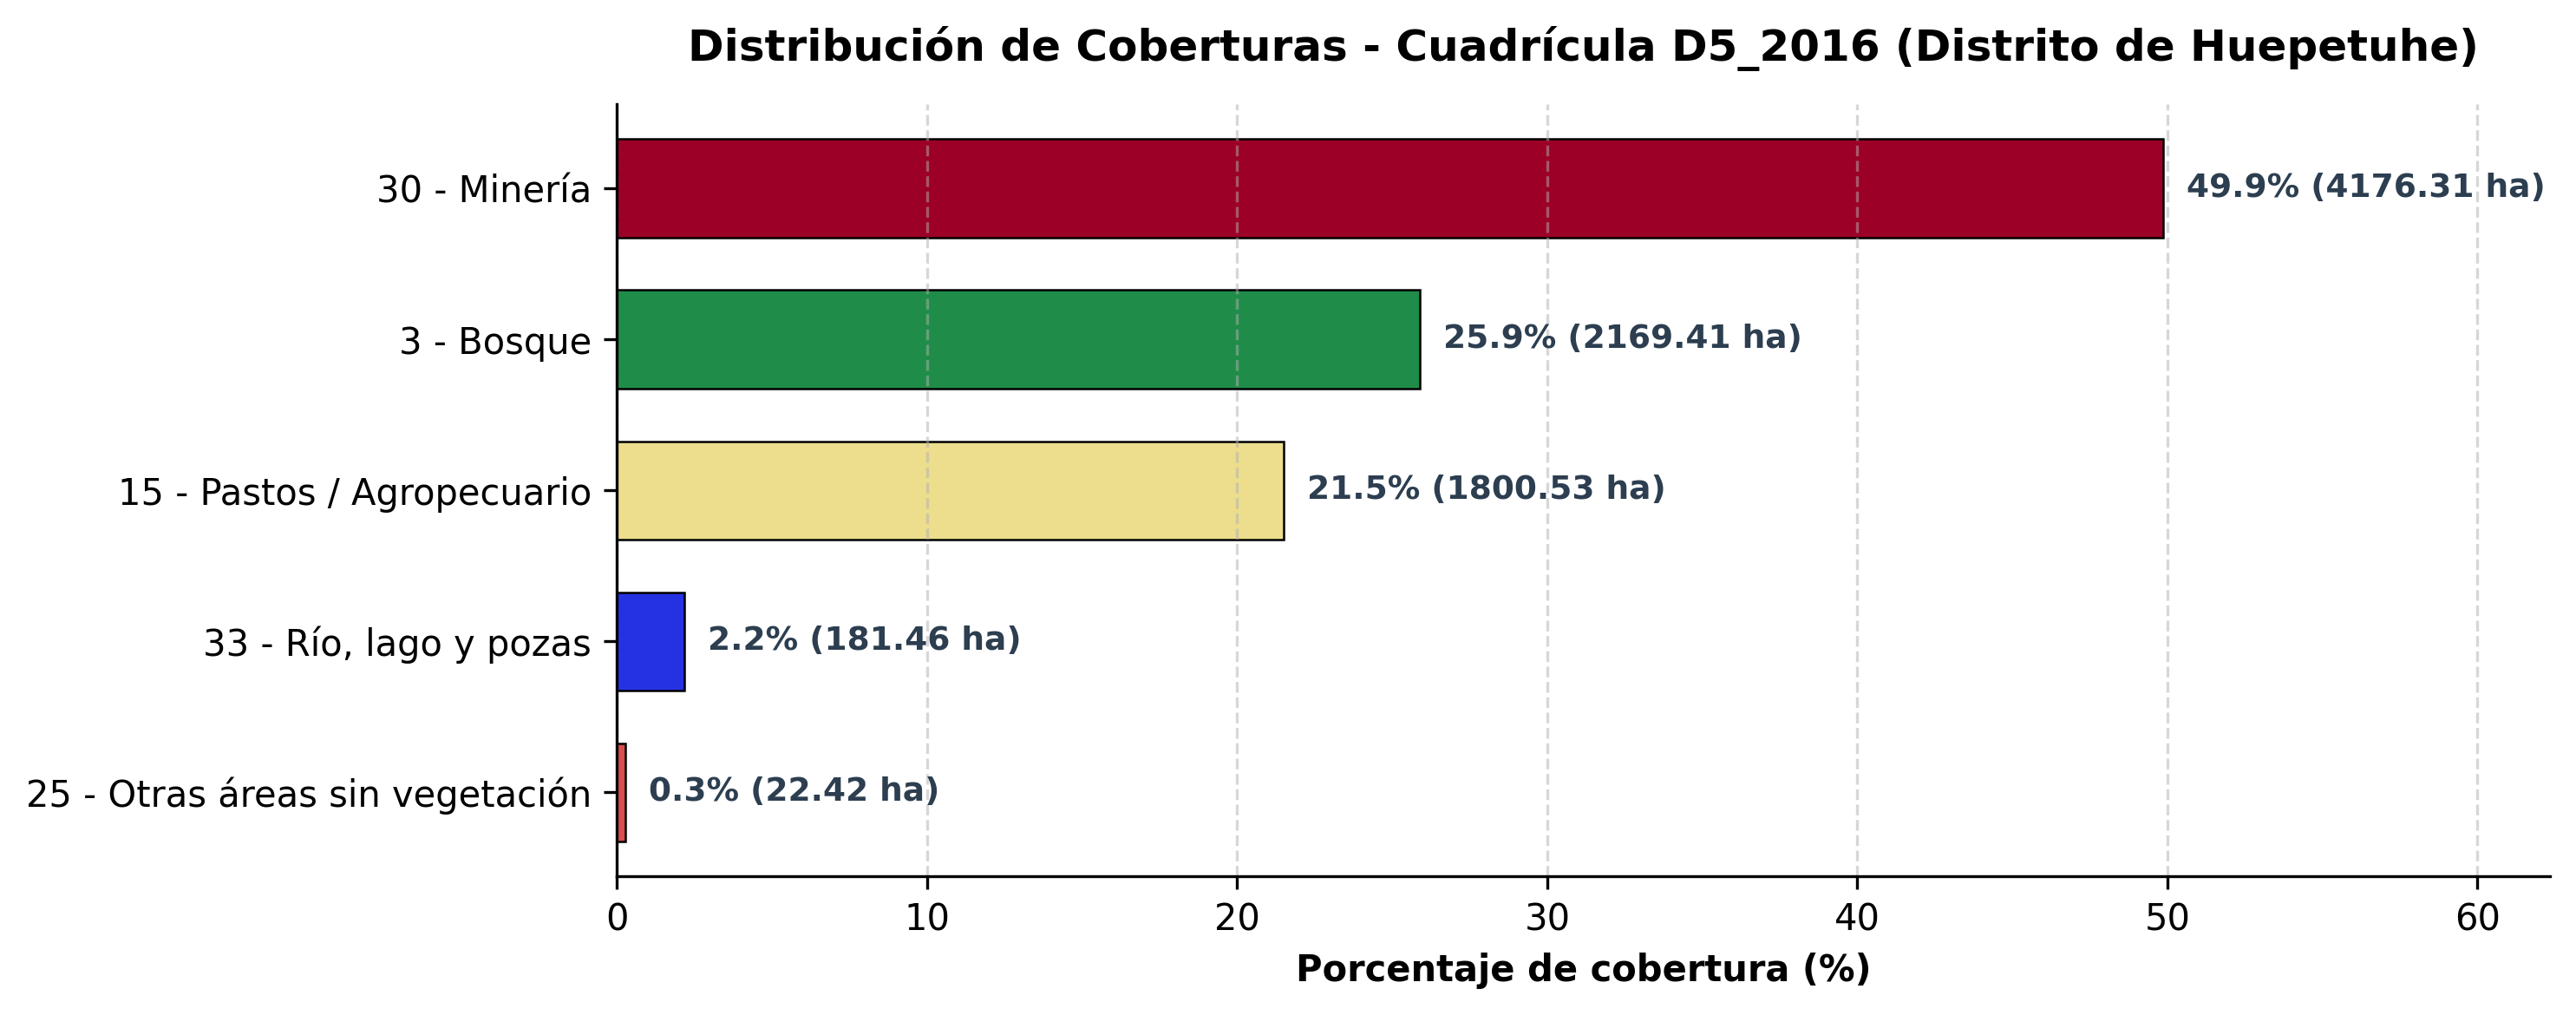

In [ ]:
# Invertir el orden para que la cobertura mayor quede arriba en el gráfico horizontal
df_plot = df_tabla_celda.iloc[::-1].reset_index(drop=True)

fig_g, ax_g = plt.subplots(figsize=(10, max(4, len(df_plot) * 0.6)), dpi=300)

barras = ax_g.barh(
    df_plot["Cobertura"],
    df_plot["Porcentaje (%)"],
    color=df_plot["Color_Hex"],
    edgecolor="black",
    linewidth=0.6,
    height=0.65
)

# Añadir etiquetas con Porcentaje y Área (ha) al final de cada barra
max_pct = df_plot["Porcentaje (%)"].max()
for barra, (_, fila) in zip(barras, df_plot.iterrows()):
    ancho_barra = barra.get_width()
    ax_g.text(
        ancho_barra + (max_pct * 0.015),
        barra.get_y() + barra.get_height() / 2,
        f"{fila['Porcentaje (%)']:.1f}% ({fila['Área (ha)']:.2f} ha)",
        va="center",
        ha="left",
        fontsize=9,
        fontweight="bold",
        color="#2c3e50"
    )

# Ajustar límites y estética siguiendo el estilo de tu mapa
ax_g.set_xlim(0, max_pct * 1.25)  # Margen extra a la derecha para que no se corten los textos
ax_g.set_xlabel("Porcentaje de cobertura (%)", fontsize=10, fontweight="bold")
ax_g.set_title(
    f"Distribución de Coberturas - Cuadrícula {id_top1}_2016 (Distrito de Huepetuhe)",
    fontsize=12,
    fontweight="bold",
    pad=12
)

ax_g.grid(axis="x", linestyle="--", alpha=0.5)
ax_g.spines["top"].set_visible(False)
ax_g.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(f"Grafico_Coberturas_{id_top1}_2016_Huepetuhe.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()